The goal of this notebook is to annotate neuronal cell types in an ABC-like fashion.

While our cell type IDs will be kept, cell type labels are inherited from ABC if propagated subclasses/supertypes match HypoMap3D's L2/L3 cell types well. Further, many:1 mappings will be deduplicated, and HypoMap3D cell types not matching ABC's receive labels integrating into ABC's annotation scheme. 

Lastly, starting at L4, clusters are not mapped to ABC but receive de novo suffixes independent of any potential matching to existing ABC clusters. 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import re
from pathlib import Path
import tqdm
from collections import Counter, defaultdict
from typing import Literal, Dict, List
import os

import pandas as pd
import scanpy as sc 
import anndata as ad 
import numpy as np 
from dotenv import dotenv_values

from hm3d_utils.utils import ClusterTree, combine_cluster_nodes
from hm3d_utils.statistics import find_markers

sc.set_figure_params(frameon=False, dpi=150, figsize=(5,5))

In [3]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

# markers
CLUSTERING_DIR = DATADIR / "5_clustering"
MARKERS_FP = CLUSTERING_DIR / 'HypoMap3D_marker_genes_qc.csv'

# adata
ADATA_FP = DATADIR / "6_NC_projection" / "all_integrated" / "HypoMap3D_full.h5ad"

# regions
REGIONS_FP = DATADIR / "7_spatial" / "analyses" / "regionwise_rm_all_wo_root_or_fibers_or_HYacro.csv"

# out
OUTDIR = DATADIR / "8_annotation"
# Create the directory if it doesn't exist
OUTDIR.mkdir(parents=True, exist_ok=True)

## Let's load and preprocess all necessary data

### adata 

In [4]:

print("loading anndata")
adata = sc.read_h5ad(ADATA_FP, backed="r")
adata = adata[(adata.obs.IsControl) & (~adata.obs.L1.str.contains("NN")),:].to_memory() # subset to neuronal control cells


loading anndata


In [5]:

print("normalizing")
# keep raw counts
adata.layers["raw"] = adata.X.copy()

# get CP10K as our find_markers function's returned specificity values are optimized for this normalization
sc.pp.normalize_total(adata, target_sum = 10_000)

adata.layers["log1p"] = adata.X.copy() # put log1p into layer as markers run on non log space
sc.pp.log1p(adata, base=2, layer="log1p")


normalizing


In [6]:
adata

AnnData object with n_obs × n_vars = 607093 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'L1', 'L2', 'L3', 'L4', 'L5', 'C66_named_propagated', 'C185_named_propagated', 'C286_named_propagated', 'C465_named_propagated', 'class_id_label_propagated', 'subclass_id_label_propagated', 'supertype_id_label_propagated', 'cluster_id_label_propagated', 'XistExpressing', 'UtyExpressing', 'sex_per_sample_inferred', 'xist_pct_per_sample', 'uty_pct_per_sample', 'L1_descr_v0.6', 'L2_descr_v0.6', 'L3_descr_v0.6', 'L4_descr_v0.6', 'L5_descr_v0.6', 'L2_prelim', 'L3_prelim', 'L4_prelim', 'L5_prelim'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTF

In [7]:
gene_metadata = adata.var.reset_index()
gene_metadata = gene_metadata.rename(columns={"index": "gene_name", })
further_exclude_mask = (
    gene_metadata["gene_name"].str.contains(r"Pde|Cntn|St18|C1q", regex=True, na=False)
    |
    gene_metadata["gene_name"].str.contains(r"\d+ot$", regex=True, na=False)
    |
    gene_metadata["gene_name"].str.contains(r"^[A-Z]{2}", regex=True, na=False)
)
furter_exclude_genes = gene_metadata.loc[further_exclude_mask, "gene_name"].to_list()

adata.var.loc[furter_exclude_genes, "IsAnnotationExcludedGene"] = True
adata.var.loc[furter_exclude_genes, "IsPriorityGene"] = False
adata.var.loc[furter_exclude_genes, "IsTopGene"] = False

### region predictions

In [8]:
regions = pd.read_csv(REGIONS_FP)
# filter to L2 neuronal labels 
regions = regions.rename(columns={"Unnamed: 0": "cluster"})
regions = regions.loc[(regions["cluster"].str.contains("2-")) & (~regions["cluster"].str.contains("NN")),:]
regions = pd.melt(regions, id_vars="cluster", value_name="relative_mass", var_name = "acronym")
regions = regions.sort_values(by=["cluster", "relative_mass"], ascending=False)

In [9]:
regions.head()

,cluster,acronym,relative_mass
1971,Gl2-9,LHA,0.227223
7819,Gl2-9,DMH,0.073761
7615,Gl2-9,ZI,0.067902
3331,Gl2-9,MB,0.058605
1427,Gl2-9,MRN,0.039889


### markers

OneVsSister markers subset to priority genes (transcription factors, neuropeptides, ...) are used as candidates for annotation of HypoMap3D L2 clusters that do not map to ABC clusters

In [10]:
priority_genes = list(adata.var.loc[(adata.var.IsPriorityGene), :].index)

In [11]:
markers = pd.read_csv(MARKERS_FP)
# subset to OneVsSister markers and priority genes
markers = markers.loc[(markers.comparison == "OneVsSisters") & (markers.gene_name.isin(priority_genes))]

In [12]:
markers.head()

,gene_name,direction,specificity,pctA,pctB,meanA,meanB,log2FC,p,padj,VE,rank,clustering,cluster,comparison
0,Foxb1,A,6.236570,0.106480,0.003613,0.576016,0.005636,6.674614,0.0,0.0,12.376232,22,L1,Gl1-1 Glut,OneVsSisters
1,Sim1,A,5.840800,0.230684,0.005491,0.649711,0.009302,6.125616,0.0,0.0,48.814749,8,L1,Gl1-1 Glut,OneVsSisters
2,Ebf3,A,5.403689,0.138809,0.005545,0.450222,0.007784,5.853412,0.0,0.0,27.623637,20,L1,Gl1-1 Glut,OneVsSisters
4,Pitx2,A,5.156033,0.150888,0.004613,0.334066,0.007476,5.481207,0.0,0.0,22.039370,19,L1,Gl1-1 Glut,OneVsSisters
5,Uncx,A,4.950169,0.163576,0.004295,0.233522,0.006275,5.217162,0.0,0.0,32.231932,16,L1,Gl1-1 Glut,OneVsSisters


### Let's construct the clustering tree to be used when calculating markers on the fly

markers are calculated on the fly when deduplicating cluster labels when several HypoMap3D L2 clusters map to the same ABC subclass

In [13]:

tree_name = "Neurons"

labelmat = adata.obs.loc[:,  [f"L{i}" for i in range(1,6)]]

tree = ClusterTree.from_labelmat(labelmat.values, adata.obsm['X_embed'], name=tree_name)

all_clusters = tree.generate_lookup_table()
all_clusters.pop(tree_name) 

HierTreeCluster(name='Neurons', level=0, num_members=607093, supercluster='None', subclusters=[Gb1-2 GABA, Gl1-1 Glut])

### Let's get the ABC table that maps all ABC cell types within a hierarchy

In [14]:
ALLEN_TABLE_FP = os.path.join(OUTDIR, "41586_2023_6812_MOESM8_ESM.xlsx")

if not os.path.isfile(ALLEN_TABLE_FP):
    !wget -P {OUTDIR} https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-023-06812-z/MediaObjects/41586_2023_6812_MOESM8_ESM.xlsx

allen_table = pd.read_excel(ALLEN_TABLE_FP)

In [15]:
#allen_table.head()

# Let's map HM3D to ABC cell types

## Starting with L2 

Here, we match ABC subclasses to HypoMap3D's L2, inheriting the name of ABC if there is at least 66% overlap. 

many:1 mappings are deduplicated by calculating marker genes between the clusters receiving the same ABC match. 

HypoMap3D clusters not receiving an annotation here are handled further down the notebook

In [16]:

def extract_numeric_id(label: str) -> int:
    """Extract numeric ID from a label like '001 CLA-EPd-CTX Car3 Glut'."""
    try:
        return int(label.split()[0].lstrip("0"))
    except (IndexError, ValueError):
        return -1


In [17]:
def deduplicate_cluster_names_lvl2(
    adata: ad.AnnData,
    cluster_to_abc: dict,
    specificity_filter: float = 1,
    pct_filter: float = 0.5,
    hierarchy_lookup=None,
    verbose: bool = False,
) -> dict:
    """
    Deduplicate cluster label names at hierarchy level 2 by appending distinguishing
    marker genes as suffixes to non-unique labels.

    When multiple clusters share the same ABC (Annotation-Based Classification) label,
    this function identifies marker genes that uniquely distinguish each cluster from
    the others sharing the same label. These genes are then appended to the shared
    label to create unique, biologically meaningful identifiers. 

    Priority is given to biologically relevant genes (transcription factors, 
    neuropeptides, neurotransmitters), and genes that are highly specific to 
    child clusters (i.e., sub-clusters in the hierarchy) are excluded to avoid 
    using overly fine-grained markers.

    Parameters
    ----------
    adata : ad.AnnData
        Annotated data matrix containing gene expression data. Expected to have:
        - ``adata.var.IsPriorityGene``: boolean column flagging priority genes
          (e.g., transcription factors, neuropeptides, neurotransmitters).
        - ``adata.var.IsAnnotationExcludedGene``: boolean column flagging genes
          that should not be used for annotation.
        - ``adata.obs`` columns named ``L{level}`` (e.g., ``L2``, ``L3``) 
          containing cluster assignments at each hierarchy level.
        - ``adata.obs["Sample"]``: column used as stratification key for 
          marker gene calculation.
    cluster_to_abc : dict
        Mapping from cluster names to their corresponding
        ABC labels. Clusters sharing the 
        same ABC label will be deduplicated.
    specificity_filter : float, optional
        Minimum specificity score threshold used to identify genes that are
        highly specific to child clusters. These genes are excluded from being
        used as distinguishing suffixes to prevent inflation of the parent 
        cluster label with overly specific sub-cluster markers. Default is ``1``.
    pct_filter : float, optional
        Minimum percentage of cells expressing a gene within a cluster,
        used to filter candidate marker genes. Passed to ``find_markers`` as
        ``min_pct_expression``. Default is ``0.5``.
    hierarchy_lookup : dict or None, optional
        A lookup structure mapping cluster names to their hierarchy node objects.
        Each node is expected to have a ``.subclusters`` attribute containing
        child cluster objects with a ``.name`` attribute. Used to identify and
        exclude genes that are specific to child clusters rather than the parent
        cluster itself. If ``None``, child-cluster exclusion is skipped.
        Default is ``None``.
    verbose : bool, optional
        If ``True``, prints detailed progress information including cluster
        processing steps, candidate genes, excluded genes, and deduplication
        attempts. Default is ``False``.

    Returns
    -------
    dict
        A dictionary mapping each original cluster name to its new, 
        deduplicated label. Clusters that did not share a label with any
        other cluster are returned with their original ABC label unchanged.
        For deduplicated clusters, the returned label is constructed by
        inserting one or more distinguishing gene names as a suffix into
        the shared ABC label (inserted before the last word of the label).

    Raises
    ------
    RuntimeError
        If unique labels cannot be generated for all clusters sharing the same
        ABC label after exhausting all candidate marker genes.
    AssertionError
        If no gene suffix is successfully inserted into a label during any
        single deduplication attempt, suggesting a misconfiguration in 
        filtering parameters.

    Notes
    -----
    - The function uses an iterative approach to relax filtering thresholds 
      (``pctB``) when fewer than 10 candidate genes are found for a cluster,
      allowing up to 10 iterations with progressively relaxed filters.
    - Gene suffixes are inserted before the last word of the ABC label.
    - Genes already present (case-insensitive) in the ABC label are not used
      as suffixes to avoid redundancy.
    - The same gene cannot be used as a distinguishing suffix for more than
      one cluster within the same ABC label group.
    """

    # get the priority genes: TFs, NPs and NTs
    priority_genes = list(adata.var.loc[(adata.var.IsPriorityGene), :].index)
    # get genes that should definitely not to be used for annotation
    not_excluded_anno_genes = list(adata.var.loc[~adata.var.IsAnnotationExcludedGene, :].index)

    if verbose:
        print("Starting deduplication...")

    abc_to_clusters = defaultdict(list)
    for cluster, abc_label in cluster_to_abc.items():
        abc_to_clusters[abc_label].append(cluster)

    final_mapping = {}

    for abc_label, clusters in abc_to_clusters.items():
        if verbose:
            print(f"\nProcessing ABC label: {abc_label}")


        if len(clusters) == 1:
            if verbose:
                print("No duplicates found. Next.")
            final_mapping[clusters[0]] = abc_label
            continue

        if verbose:
            print(f"Clusters needing deduplication: {clusters}")
        
        cluster_to_genes = {}
        for cluster in clusters:

            if verbose:
                print(f"Recalculating markers for {cluster} vs the other duplicates.")
            # recalculate marker genes vs the other clusters that we want to distinguish the current cluster from
            l_column_name = f"L{cluster[2]}" # e.g.-> L2
            self_mask = adata.obs[l_column_name] == cluster
            others = [c for c in clusters if c != cluster]
            others_mask = adata.obs[l_column_name].isin(others)
            own_genes_df = find_markers(adata_A = adata[self_mask], adata_B = adata[others_mask], 
                                        strata_key= "Sample", max_stratum_size= 1000, min_stratum_size = 5,
                                        min_pct_expression = pct_filter, min_specificity = 0.1,
                                        ).reset_index(names = "gene_name").sort_values("specificity", ascending=False)
            
            # only keep the upregulated genes, i.e., direction == adata_A
            own_genes_df = own_genes_df.loc[own_genes_df["direction"] == "A",:]
            
            # try to get at least 10 candidate genes
            candidate_genes = []
            pctB_iteration = 1
            while (len(candidate_genes) < 10) & (pctB_iteration < 10):
                pctB_filter_ = pctB_iteration * 0.05 # relax pctB filter with each iteration
                # filter for genes that are not highly expressed in B
                own_genes_df_ = own_genes_df.loc[own_genes_df["pctB"]<pctB_filter_,:]
                # keep only priority genes
                prio_genes = own_genes_df_.loc[(own_genes_df_.gene_name.isin(priority_genes)), "gene_name"].to_list()
                n_prio_genes = len(prio_genes)
                for g in prio_genes:
                    if g not in candidate_genes:
                        candidate_genes.append(g)
                pctB_iteration += 1
            if verbose:
                    print(f"{n_prio_genes} priority marker genes found for {cluster} after {pctB_iteration} iterations.")


            # Start collecting genes to exclude
            exclude_clusters = set()

            # Children
            if hierarchy_lookup and cluster in hierarchy_lookup:
                children = hierarchy_lookup[cluster].subclusters or []
                if verbose:
                    print(f"{len(children)} children detected")
                
                exclude_clusters.update(c.name for c in children if c)

            # Get genes with high specificity in any of those excluded clusters
            # if there is more than 1 child
            if len(exclude_clusters) > 1:
              
                # calculate markers for each of the exclude_clusters vs the other exclude_clusters, i.e., the children of the current cluster
                exclude_genes = set()

                # Prepare masks for comparison
                l_children_column_name = f"L{int(l_column_name[-1])+1}" # increase L level by 1 as these are the children clusters of the current cluster
                
                for ex_cluster in exclude_clusters:
                    if verbose:
                        print(f"Recalculating markers for child cluster {ex_cluster} vs the other children.")

                    compare_against = [c for c in exclude_clusters if c != ex_cluster]

                    # Build masks
                    adata.obs[l_children_column_name] = adata.obs[l_children_column_name].astype(str)  # ensure string type
                    self_mask = adata.obs[l_children_column_name] == ex_cluster 
                    others_mask = adata.obs[l_children_column_name].isin(compare_against)

                    try:
                        markers_df = find_markers(
                            adata_A=adata[self_mask],
                            adata_B=adata[others_mask],
                            strata_key="Sample",
                            max_stratum_size=1000,
                            min_stratum_size=5,
                            min_pct_expression=pct_filter,
                            min_specificity=0.1  # possibly make configurable
                        ).reset_index(names = "gene_name")

                        # Filter by specificity and only keep genes that are upregulated 
                        high_spec_genes = markers_df[(markers_df["specificity"] > specificity_filter) & (markers_df["direction"] == "A")]["gene_name"]
                        exclude_genes.update(high_spec_genes.tolist())

                    except Exception as e:
                        if verbose:
                            print(f"    Warning: run_markers failed for exclude_cluster '{ex_cluster}': {e}", flush=True)
                        continue
            else:
                if verbose:
                    print("Skipping children OvS marker gene calculation as there is only 1 child.")
                

            # Filter candidate genes for this cluster
            candidate_genes = [
                gene for gene in candidate_genes
                if gene not in exclude_genes
            ]

            cluster_to_genes[cluster] = candidate_genes

            if verbose:
                print(f"\nCluster: {cluster}")
                print(f"  Exclude clusters: {sorted(exclude_clusters)}")
                print(f"  Excluded genes: {sorted(exclude_genes)}")
                print(f"  Remaining candidate genes: {candidate_genes}")

        abc_label_lc_parts = set(part.lower() for part in abc_label.split(" "))
        used_genes = set()
        deduped_labels = {}
        cluster_suffixes = {cluster: [] for cluster in clusters}

        max_genes = max(len(genes) for genes in cluster_to_genes.values()) + 2
        attempts = 0

        while True:
            deduped_labels.clear()
            local_used_genes = set()

            if verbose:
                print(f"\nAttempt {attempts + 1}/{max_genes} for label '{abc_label}'")

            for cluster in clusters:
                suffix = cluster_suffixes[cluster]
                gene_list = cluster_to_genes[cluster]

                if verbose:
                    print(f"  Cluster {cluster} gene candidates: {gene_list}")

                for gene in gene_list:
                    gene_lc = gene.lower()

                    if (gene_lc not in abc_label_lc_parts and
                        gene not in suffix and
                        gene not in used_genes and
                        gene not in local_used_genes):

                        suffix.append(gene)
                        local_used_genes.add(gene)
                        if verbose:
                            print(f"    Added gene '{gene}' to label for cluster {cluster}")
                        break
                    elif verbose:
                        print(f"    Skipped gene '{gene}' (already used or in label)")

                parts = abc_label.split(" ")
                new_label = " ".join(parts[:-1] + suffix + [parts[-1]]) if len(parts) > 1 else " ".join(suffix + [abc_label])
                deduped_labels[cluster] = new_label
                assert new_label != abc_label, "No gene inserted. Something must be off. Check your parameters."

            if verbose:
                print(f"    Current deduplicated labels: {deduped_labels}")

            if len(set(deduped_labels.values())) == len(clusters):
                if verbose:
                    print("    All labels unique!")
                for cluster in clusters:
                    used_genes.update(cluster_suffixes[cluster])
                break

            attempts += 1
            if attempts > max_genes:
                raise RuntimeError(f"Could not deduplicate label '{abc_label}' after {max_genes} attempts.")

        final_mapping.update(deduped_labels)

    return final_mapping


In [18]:
def get_mapping_lvl2(
    adata: ad.AnnData,
    l2_column: str = "L2",
    abc_subclass_column: str = "subclass_id_label_propagated",
    overlap_threshold: float = 0.66,
    deduplicate: bool = True,
    specificity_filter: float = 1,
    pct_filter: float = 0.5,
    verbose: bool = False,
    hierarchy_lookup=None,
) -> Dict[str, str]:
    """
    Generate a mapping from L2 clusters to ABC subclass labels by computing
    a normalized confusion matrix and optionally deduplicating shared labels.

    For each level-2 cluster, the ABC subclass label with the highest fractional
    overlap is assigned, provided it exceeds a minimum overlap threshold. If
    multiple clusters are assigned the same ABC label, an optional deduplication
    step appends distinguishing marker gene suffixes to each shared label to
    ensure all cluster labels remain unique and biologically informative.

    Parameters
    ----------
    adata : ad.AnnData
        Annotated data matrix. Must contain an ``obs`` DataFrame with at least:
        - A column named by ``l2_column`` containing level-2 cluster assignments.
        - A column named by ``abc_subclass_column`` containing ABC subclass
          label assignments (e.g., propagated from a reference atlas).
        Additional columns and expression data are passed to 
        ``deduplicate_cluster_names_lvl2`` if ``deduplicate=True``.
    l2_column : str, optional
        Name of the column in ``adata.obs`` containing the level-2 cluster
        assignments. Default is ``"L2"``.
    abc_subclass_column : str, optional
        Name of the column in ``adata.obs`` containing the ABC subclass labels
        to map to. Default is ``"subclass_id_label_propagated"``.
    overlap_threshold : float, optional
        Minimum fractional overlap (between 0 and 1) required for a level-2
        cluster to be assigned an ABC subclass label. Clusters where no ABC
        label exceeds this threshold are excluded from the final mapping.
        Default is ``0.66``.
    deduplicate : bool, optional
        If ``True``, applies ``deduplicate_cluster_names_lvl2`` to resolve cases
        where multiple level-2 clusters are assigned the same ABC subclass label,
        appending distinguishing marker gene suffixes to create unique labels.
        If ``False``, the raw confusion-matrix-based mapping is returned as-is,
        which may contain duplicate label assignments. Default is ``True``.
    specificity_filter : float, optional
        Minimum specificity score threshold passed to
        ``deduplicate_cluster_names_lvl2`` for filtering child-cluster-specific
        genes during deduplication. Only used when ``deduplicate=True``.
        Default is ``1``.
    pct_filter : float, optional
        Minimum percentage of cells expressing a gene, passed to
        ``deduplicate_cluster_names_lvl2`` as ``min_pct_expression`` when
        computing marker genes during deduplication. Only used when
        ``deduplicate=True``. Default is ``0.5``.
    verbose : bool, optional
        If ``True``, prints progress and diagnostic information during both
        the mapping and deduplication steps. Default is ``False``.
    hierarchy_lookup : dict or None, optional
        A lookup structure mapping cluster names to hierarchy node objects with
        child cluster information. Passed directly to
        ``deduplicate_cluster_names_lvl2`` to exclude child-cluster-specific
        genes during deduplication. If ``None``, child-cluster exclusion is
        skipped. Default is ``None``.

    Returns
    -------
    Dict[str, str]
        A dictionary mapping each level-2 cluster name (str) to its assigned
        ABC subclass label (str). If ``deduplicate=True``, labels that were
        shared across multiple clusters will have distinguishing gene suffixes
        appended. Clusters that do not meet the ``overlap_threshold`` are
        excluded from the returned mapping.

    Notes
    -----
    - The overlap is computed as a row-normalized confusion matrix between
      ``l2_column`` and ``abc_subclass_column``, where each row represents the
      fraction of cells in a given level-2 cluster assigned to each ABC subclass.
    - Clusters failing the ``overlap_threshold`` are silently excluded from the
      final mapping. Consider inspecting the confusion matrix directly if
      unexpected clusters are missing from the output.
    - When ``deduplicate=False``, the returned mapping may contain multiple
      clusters pointing to the same ABC label, which may cause issues in
      downstream analyses that expect unique label assignments.
    """

    # Copy obs to avoid modifying original data
    data = adata.obs.copy()

    # get ABC matches from confusion matrix
    confusion = pd.crosstab(
        data[l2_column],
        data[abc_subclass_column],
        normalize='index'
    )

    final_map = {
        l2: row.idxmax()
        for l2, row in confusion.iterrows()
        if row.max() > overlap_threshold
    }

    # Optionally apply deduplication (if multiple clusters map to the same label)
    if deduplicate:
        final_map = deduplicate_cluster_names_lvl2(cluster_to_abc = final_map,
                specificity_filter = specificity_filter, pct_filter = pct_filter,
                verbose = verbose, hierarchy_lookup=hierarchy_lookup, 
                adata = adata)

    return final_map


In [19]:
subclass_mapper = get_mapping_lvl2(
    adata=adata,
    l2_column = "L2",
    abc_subclass_column ="subclass_id_label_propagated",
    overlap_threshold = 0.66,
    deduplicate = True,
    specificity_filter = 1,
    pct_filter = 0.25,
    verbose=True,
    hierarchy_lookup = all_clusters,
) 


Starting deduplication...

Processing ABC label: 085 SI-MPO-LPO Lhx8 Gaba
No duplicates found. Next.

Processing ABC label: 103 PVHd-DMH Lhx6 Gaba
No duplicates found. Next.

Processing ABC label: 101 ZI Pax6 Gaba
Clusters needing deduplication: ['Gb2-41', 'Gb2-50']
Recalculating markers for Gb2-41 vs the other duplicates.
16 priority marker genes found for Gb2-41 after 4 iterations.
6 children detected
Recalculating markers for child cluster Gb3-135 vs the other children.
Recalculating markers for child cluster Gb3-136 vs the other children.
Recalculating markers for child cluster Gb3-133 vs the other children.
Recalculating markers for child cluster Gb3-137 vs the other children.
Recalculating markers for child cluster Gb3-138 vs the other children.
Recalculating markers for child cluster Gb3-134 vs the other children.

Cluster: Gb2-41
  Exclude clusters: ['Gb3-133', 'Gb3-134', 'Gb3-135', 'Gb3-136', 'Gb3-137', 'Gb3-138']
  Excluded genes: ['Abca1', 'Adamtsl1', 'Adrb1', 'Amz1', 'C1ql1

In [20]:
len(subclass_mapper.keys()), adata.obs.L2.nunique(), len(subclass_mapper.keys()) / adata.obs.L2.nunique()

(58, 68, 0.8529411764705882)

In [21]:
adata.uns["abc_mapping"] = {}
adata.obs["dedup_subclass"] = adata.obs["L2"].map(subclass_mapper)
adata.uns["abc_mapping"]["subclass"] = subclass_mapper

### Let's plot the genes used for deduplication of labels

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


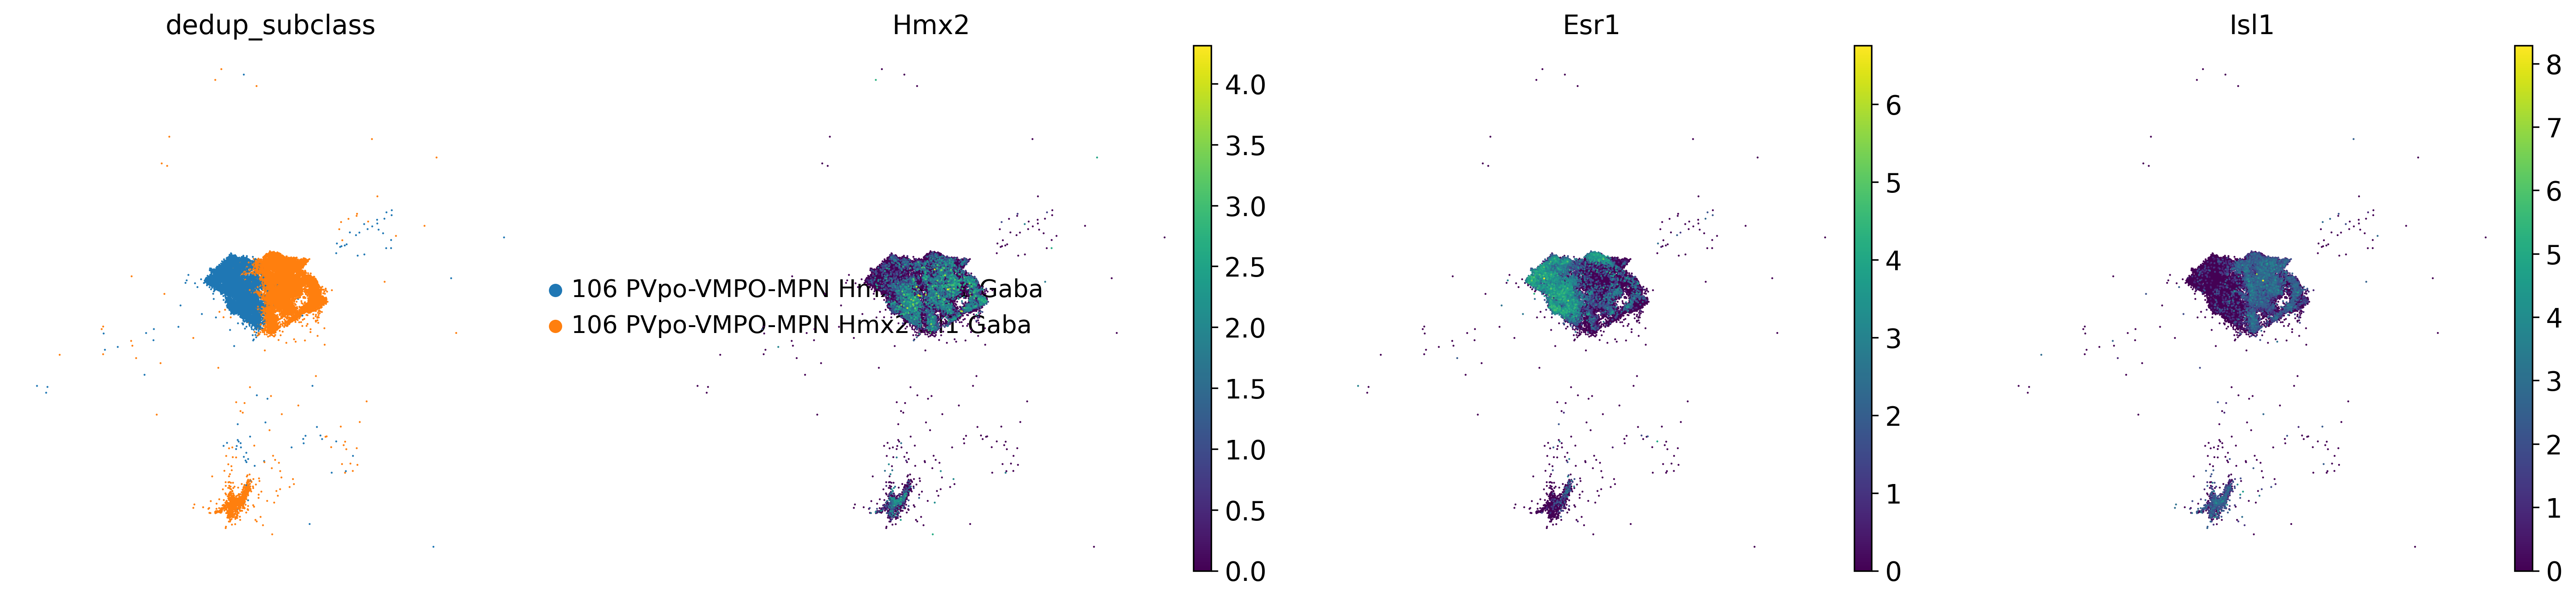

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


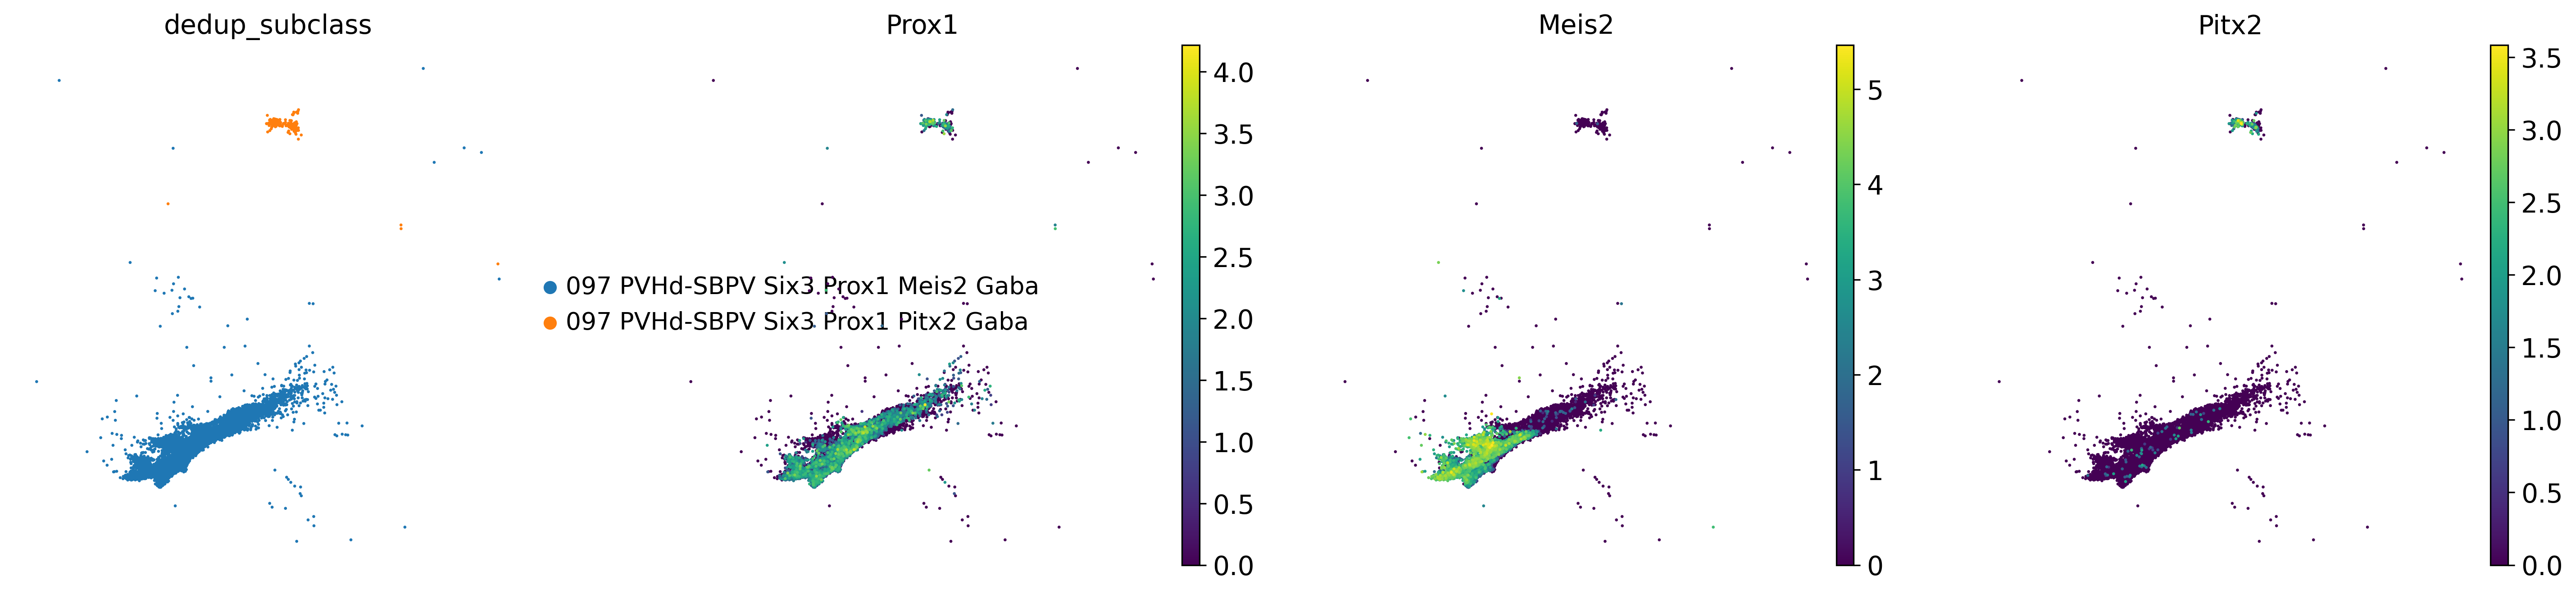

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


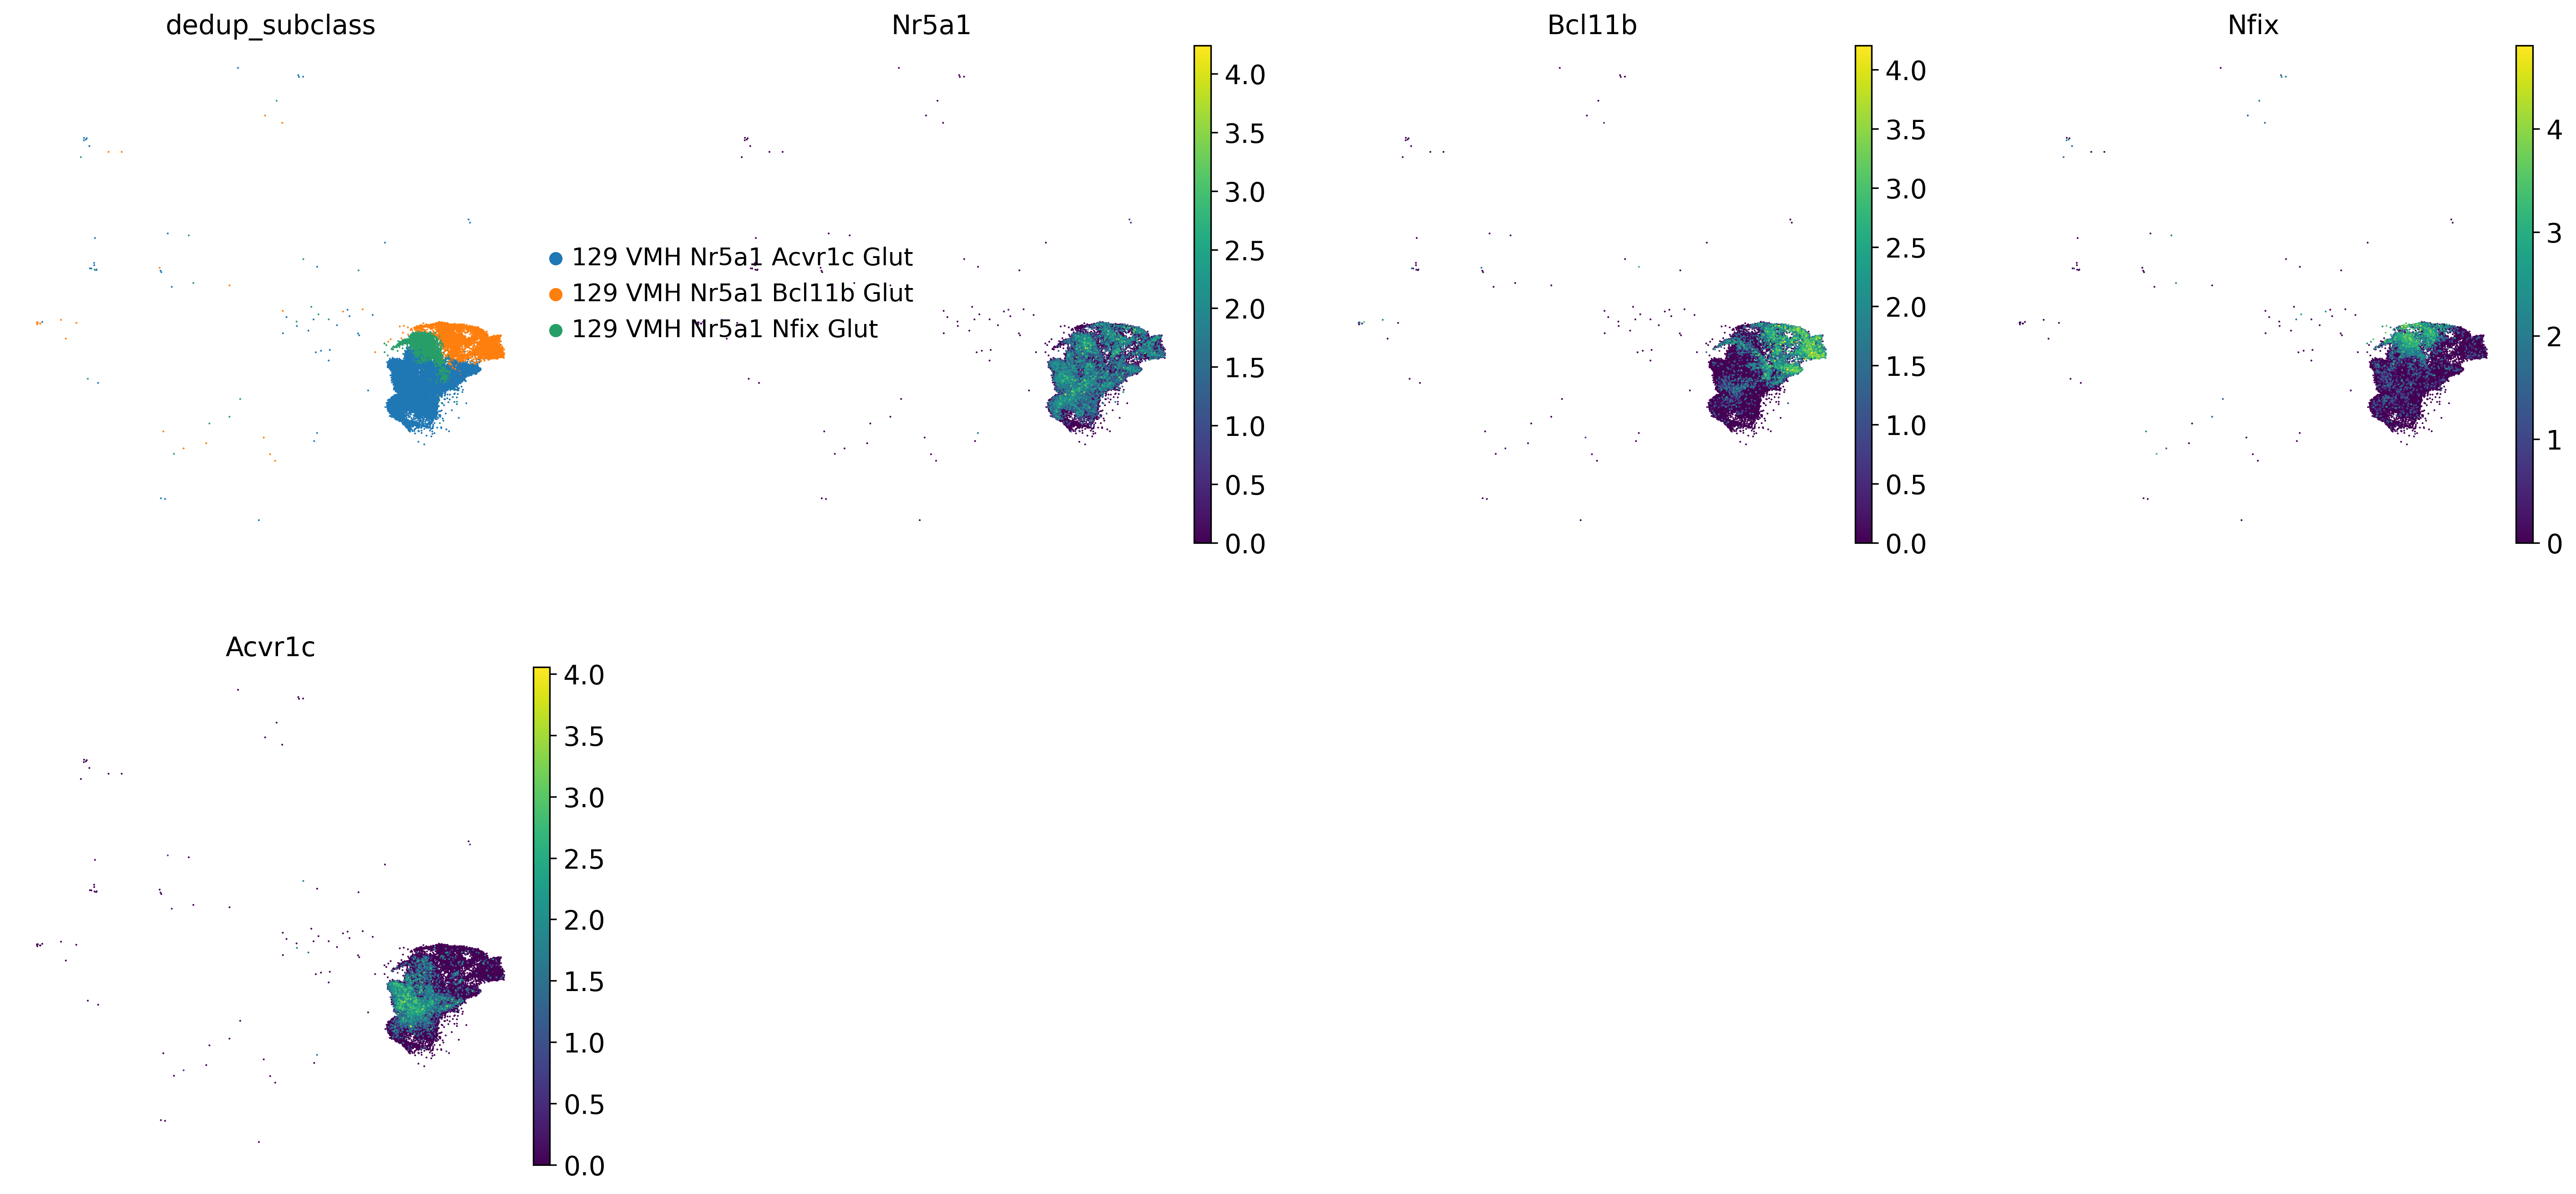

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


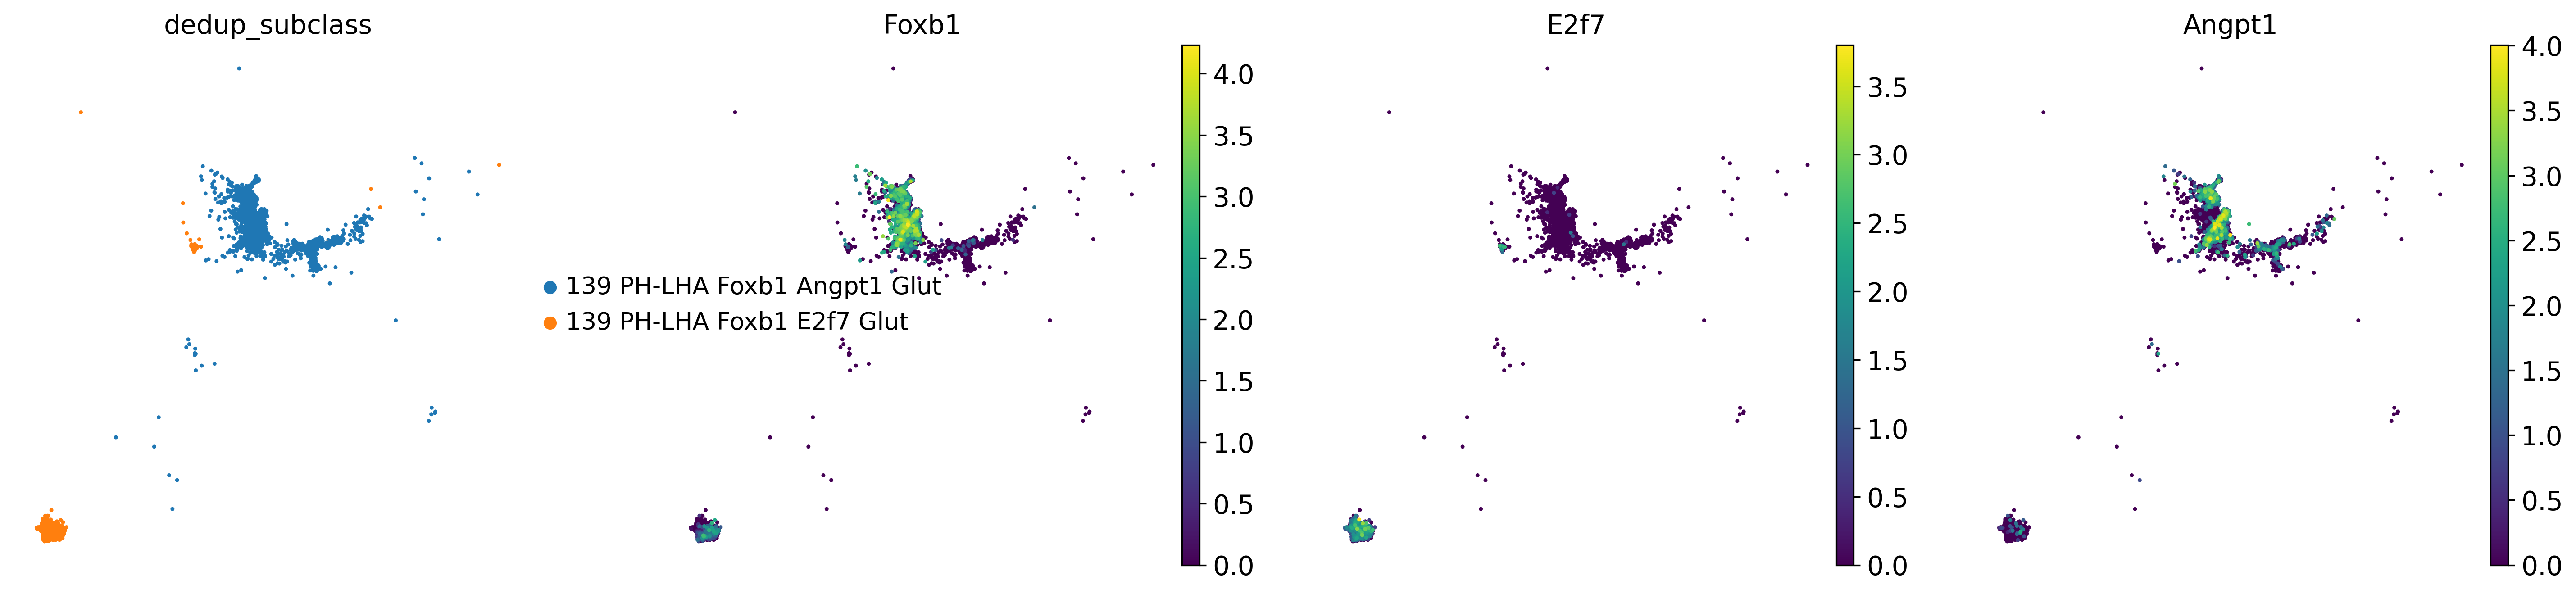

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


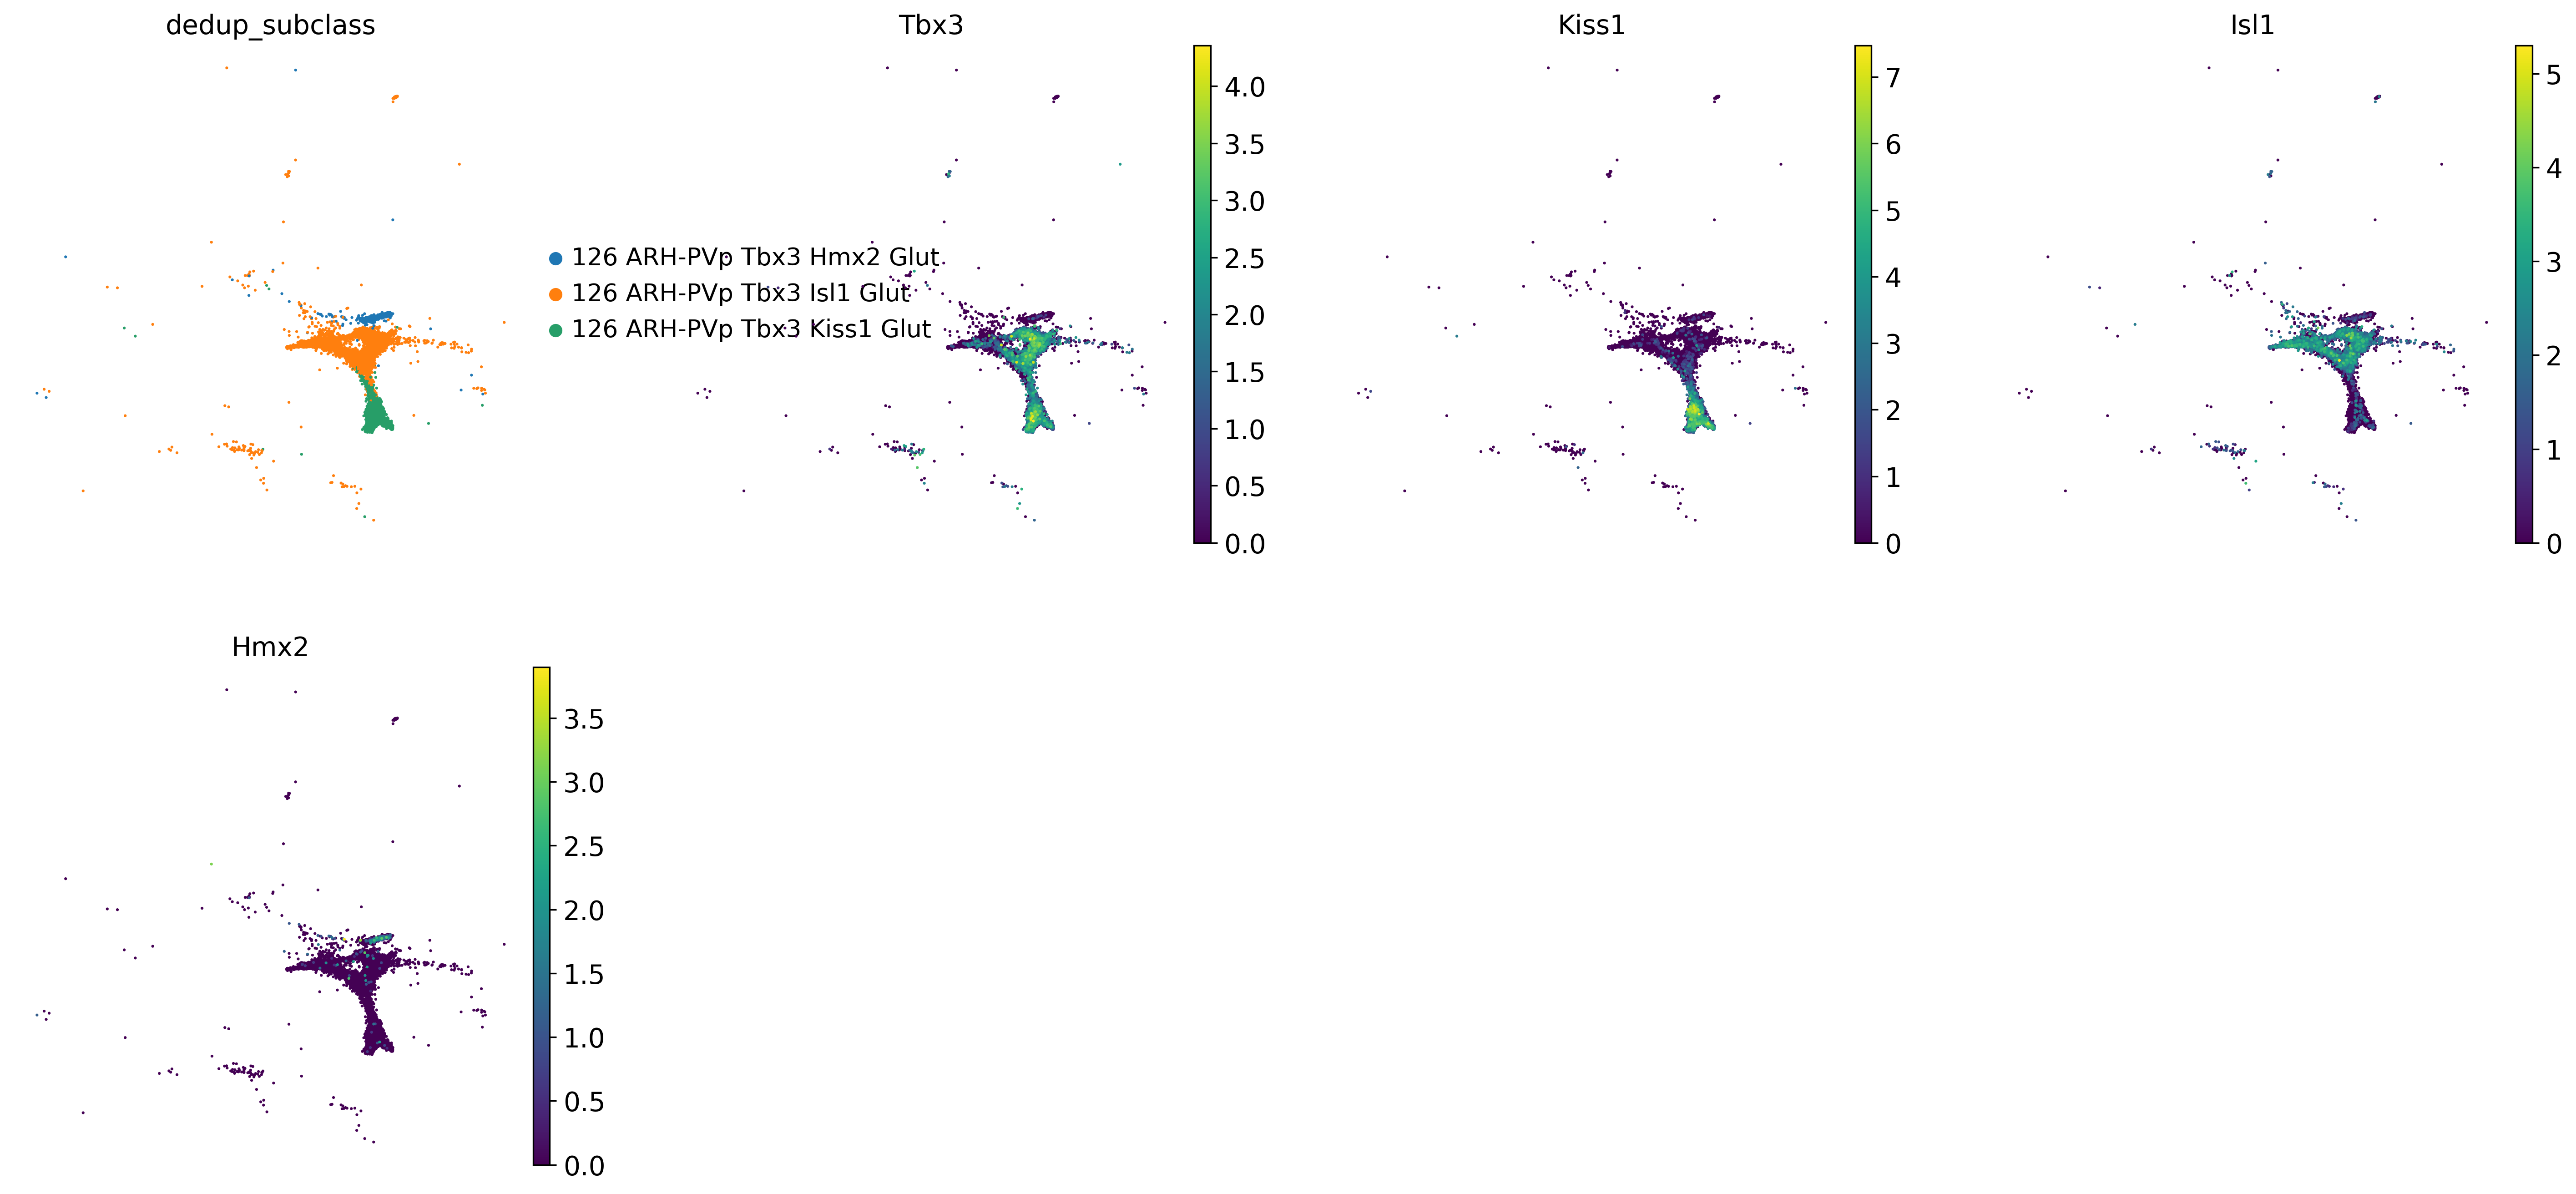

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


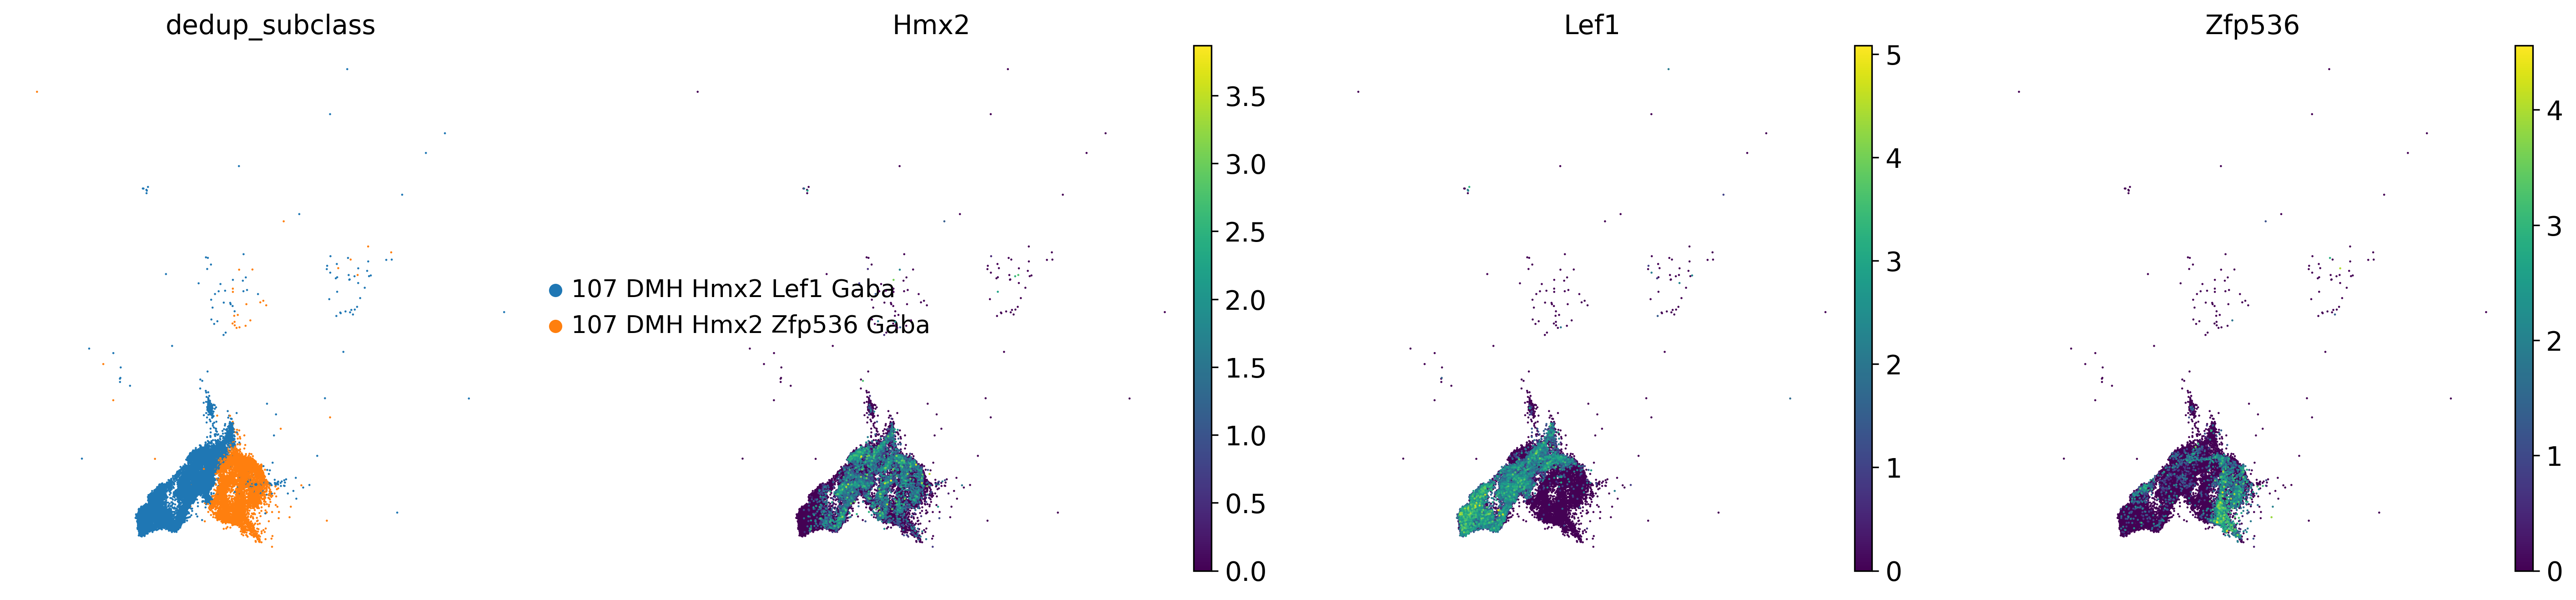

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


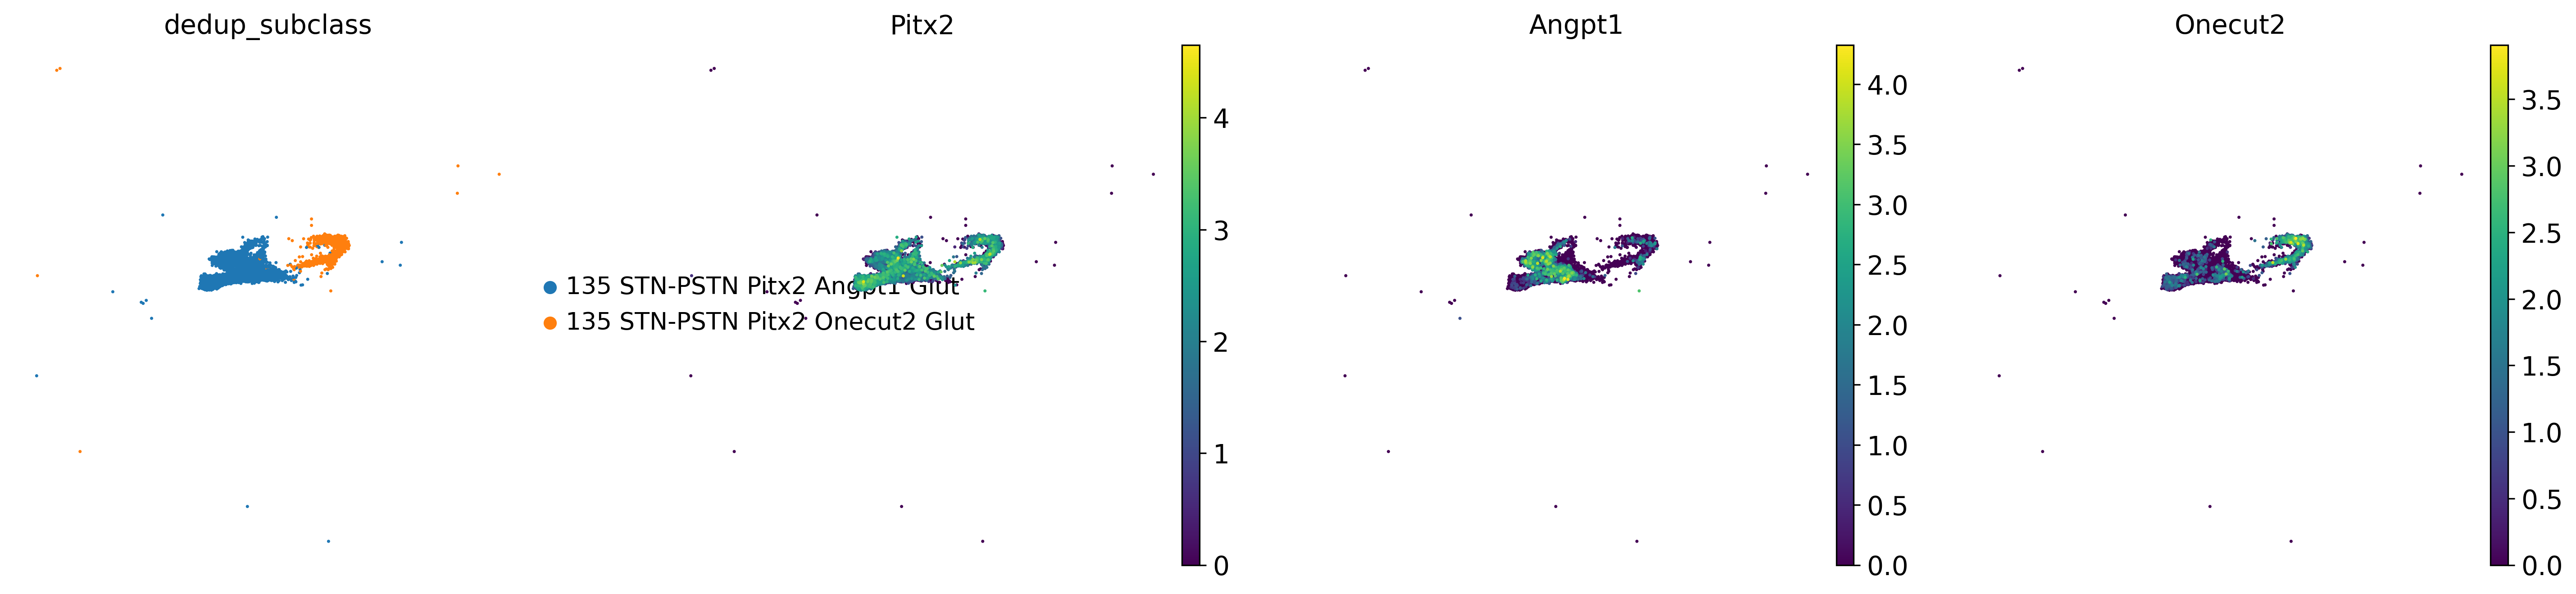

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


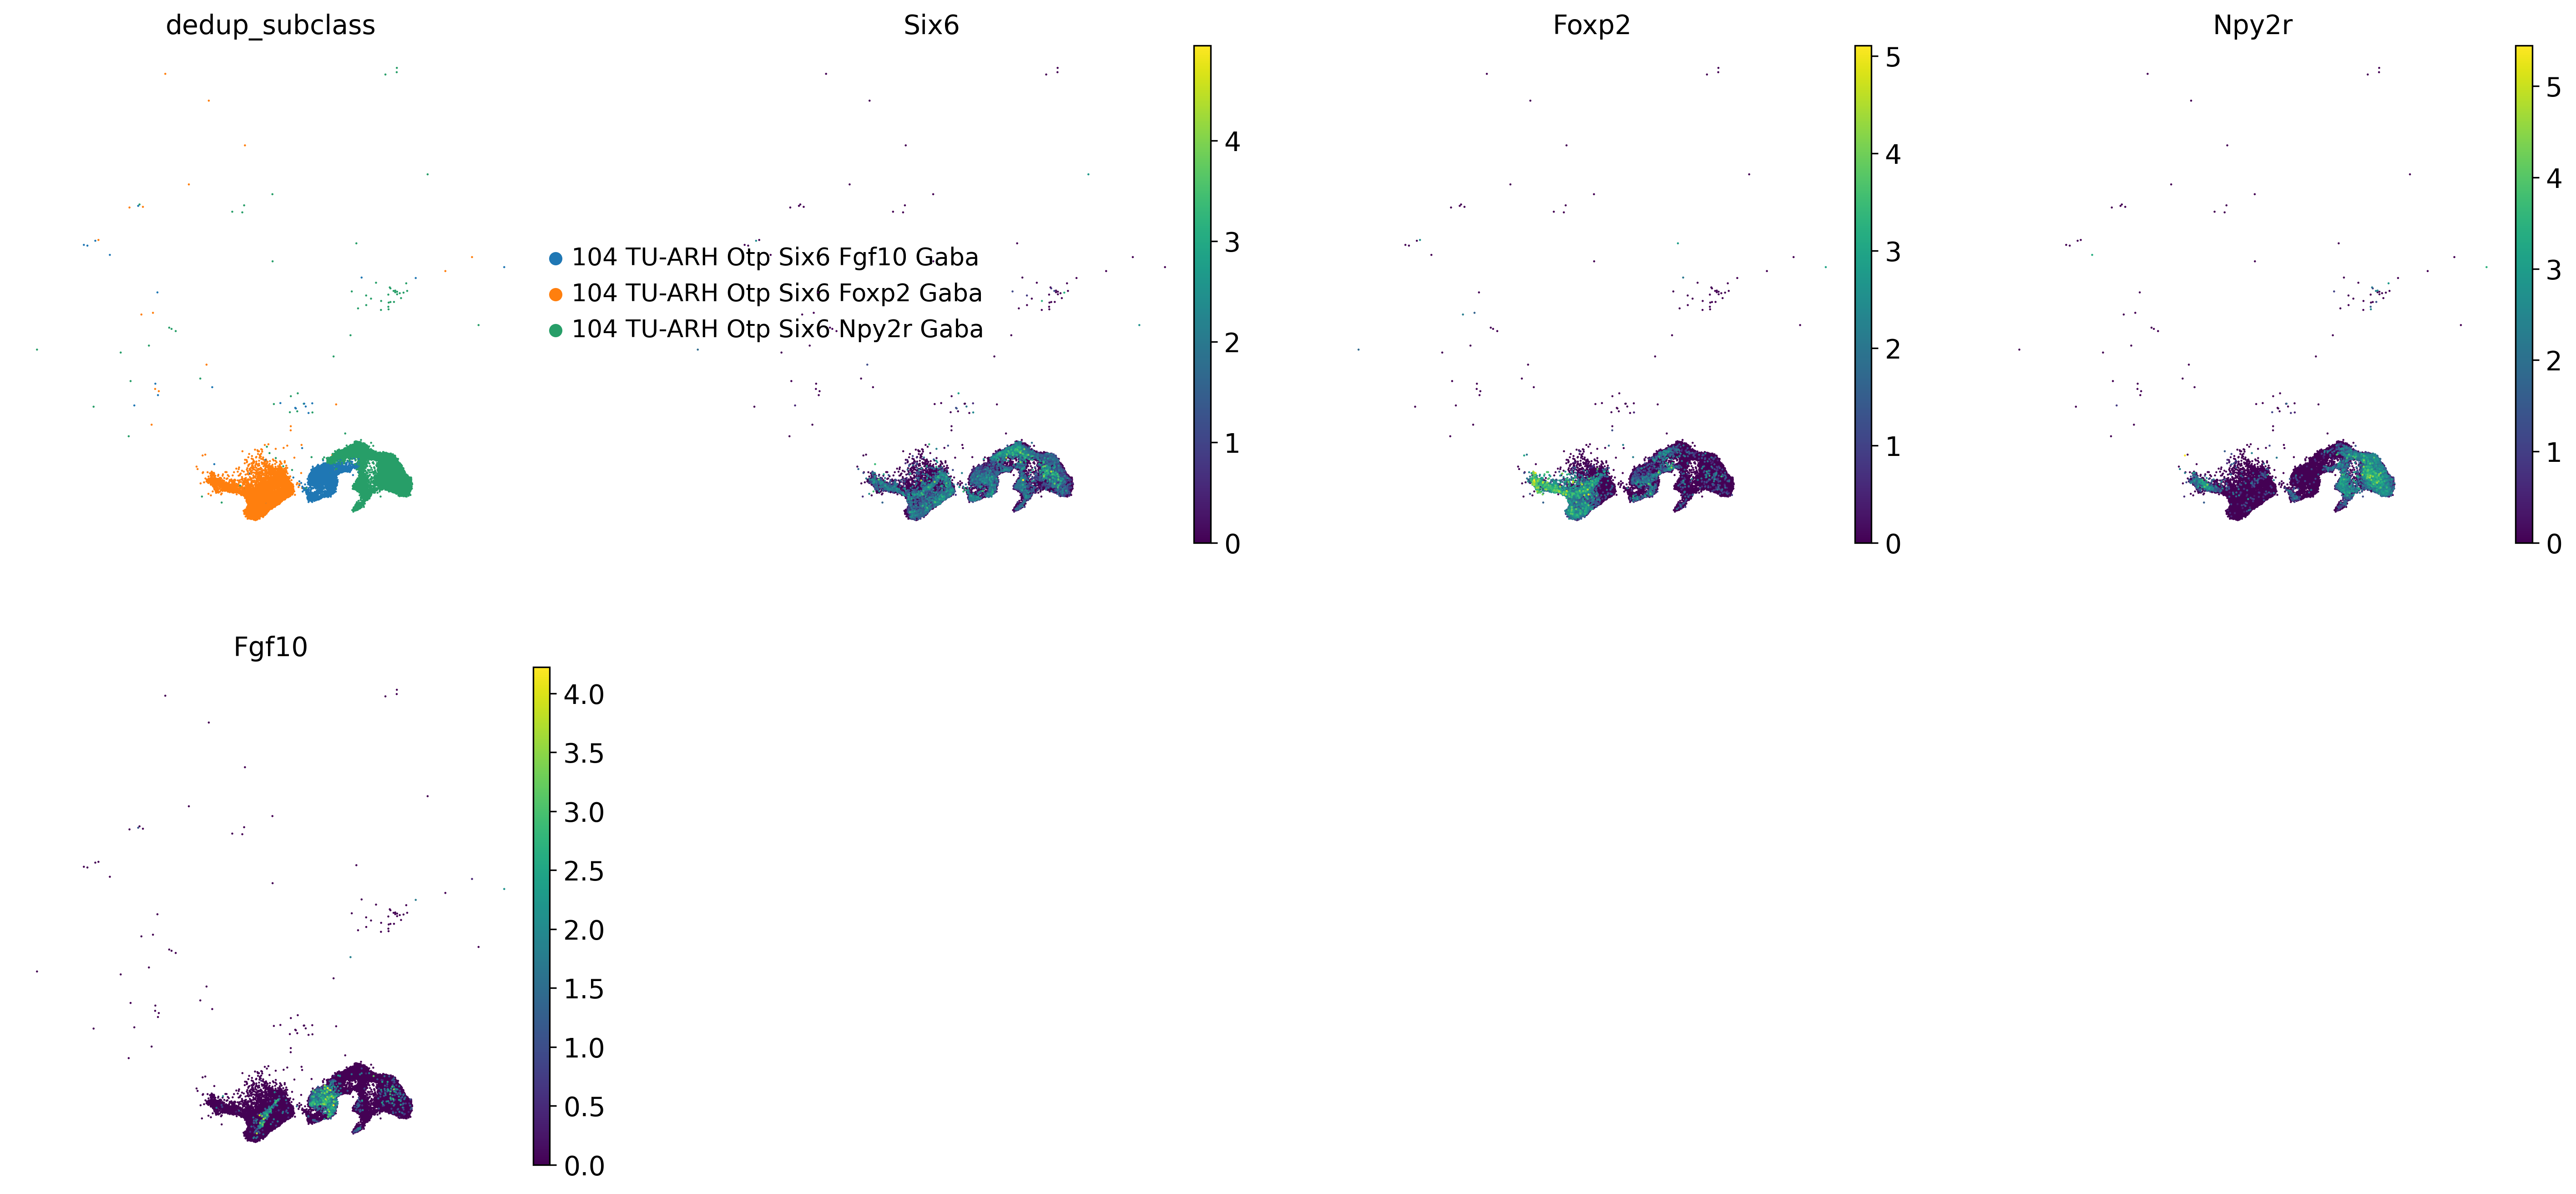

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


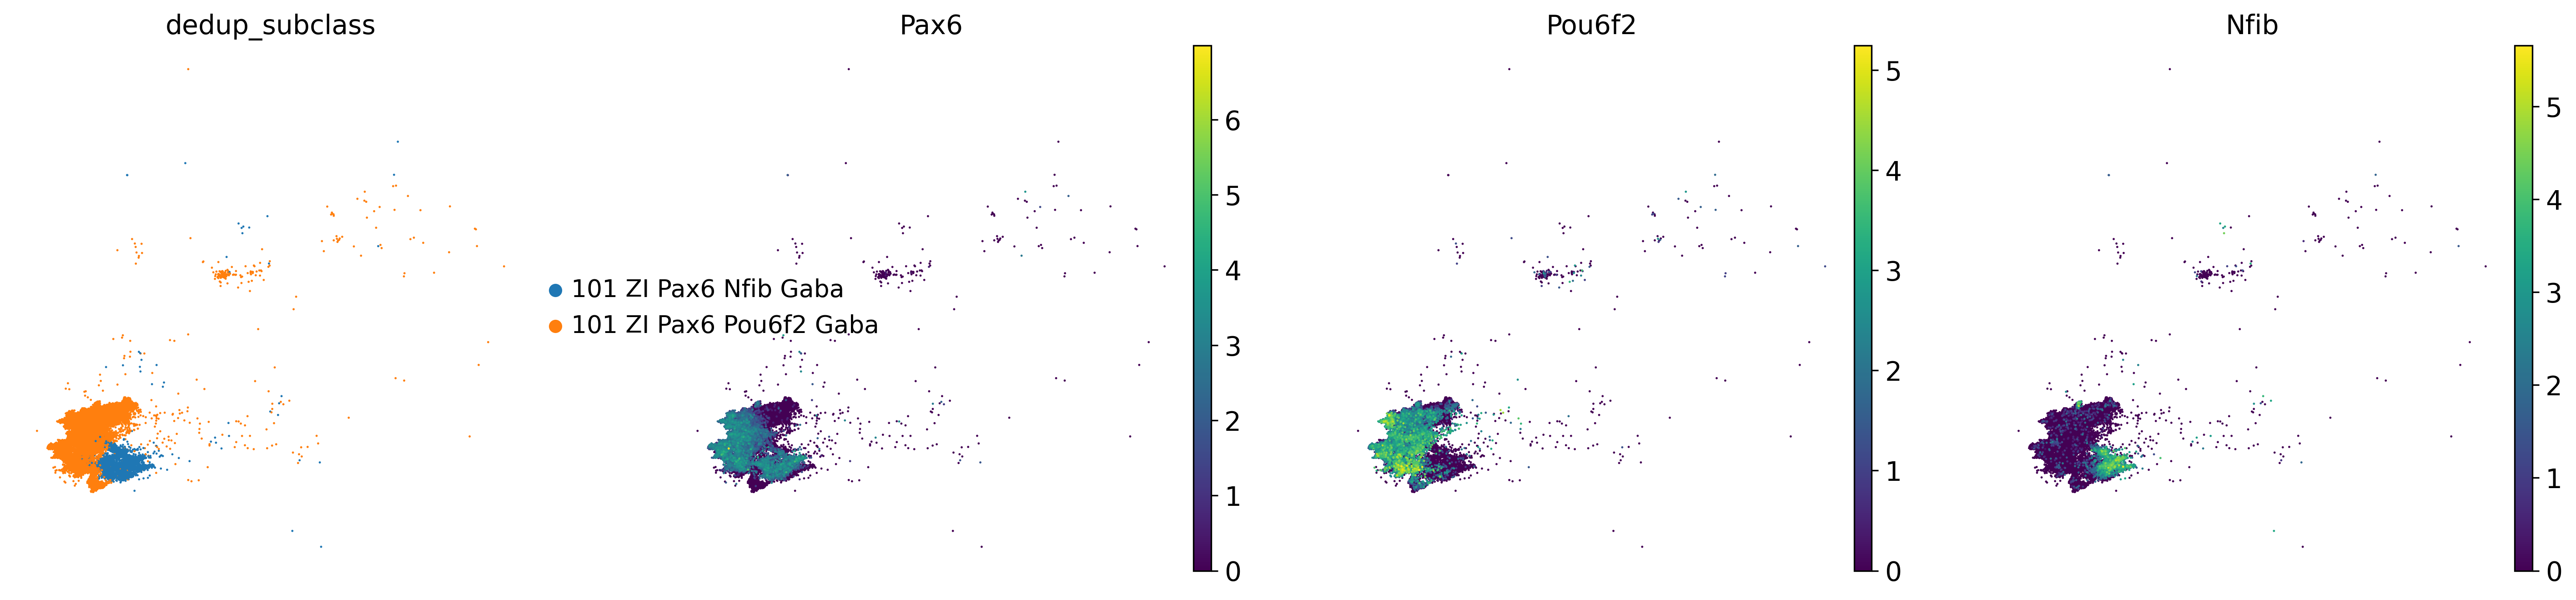

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


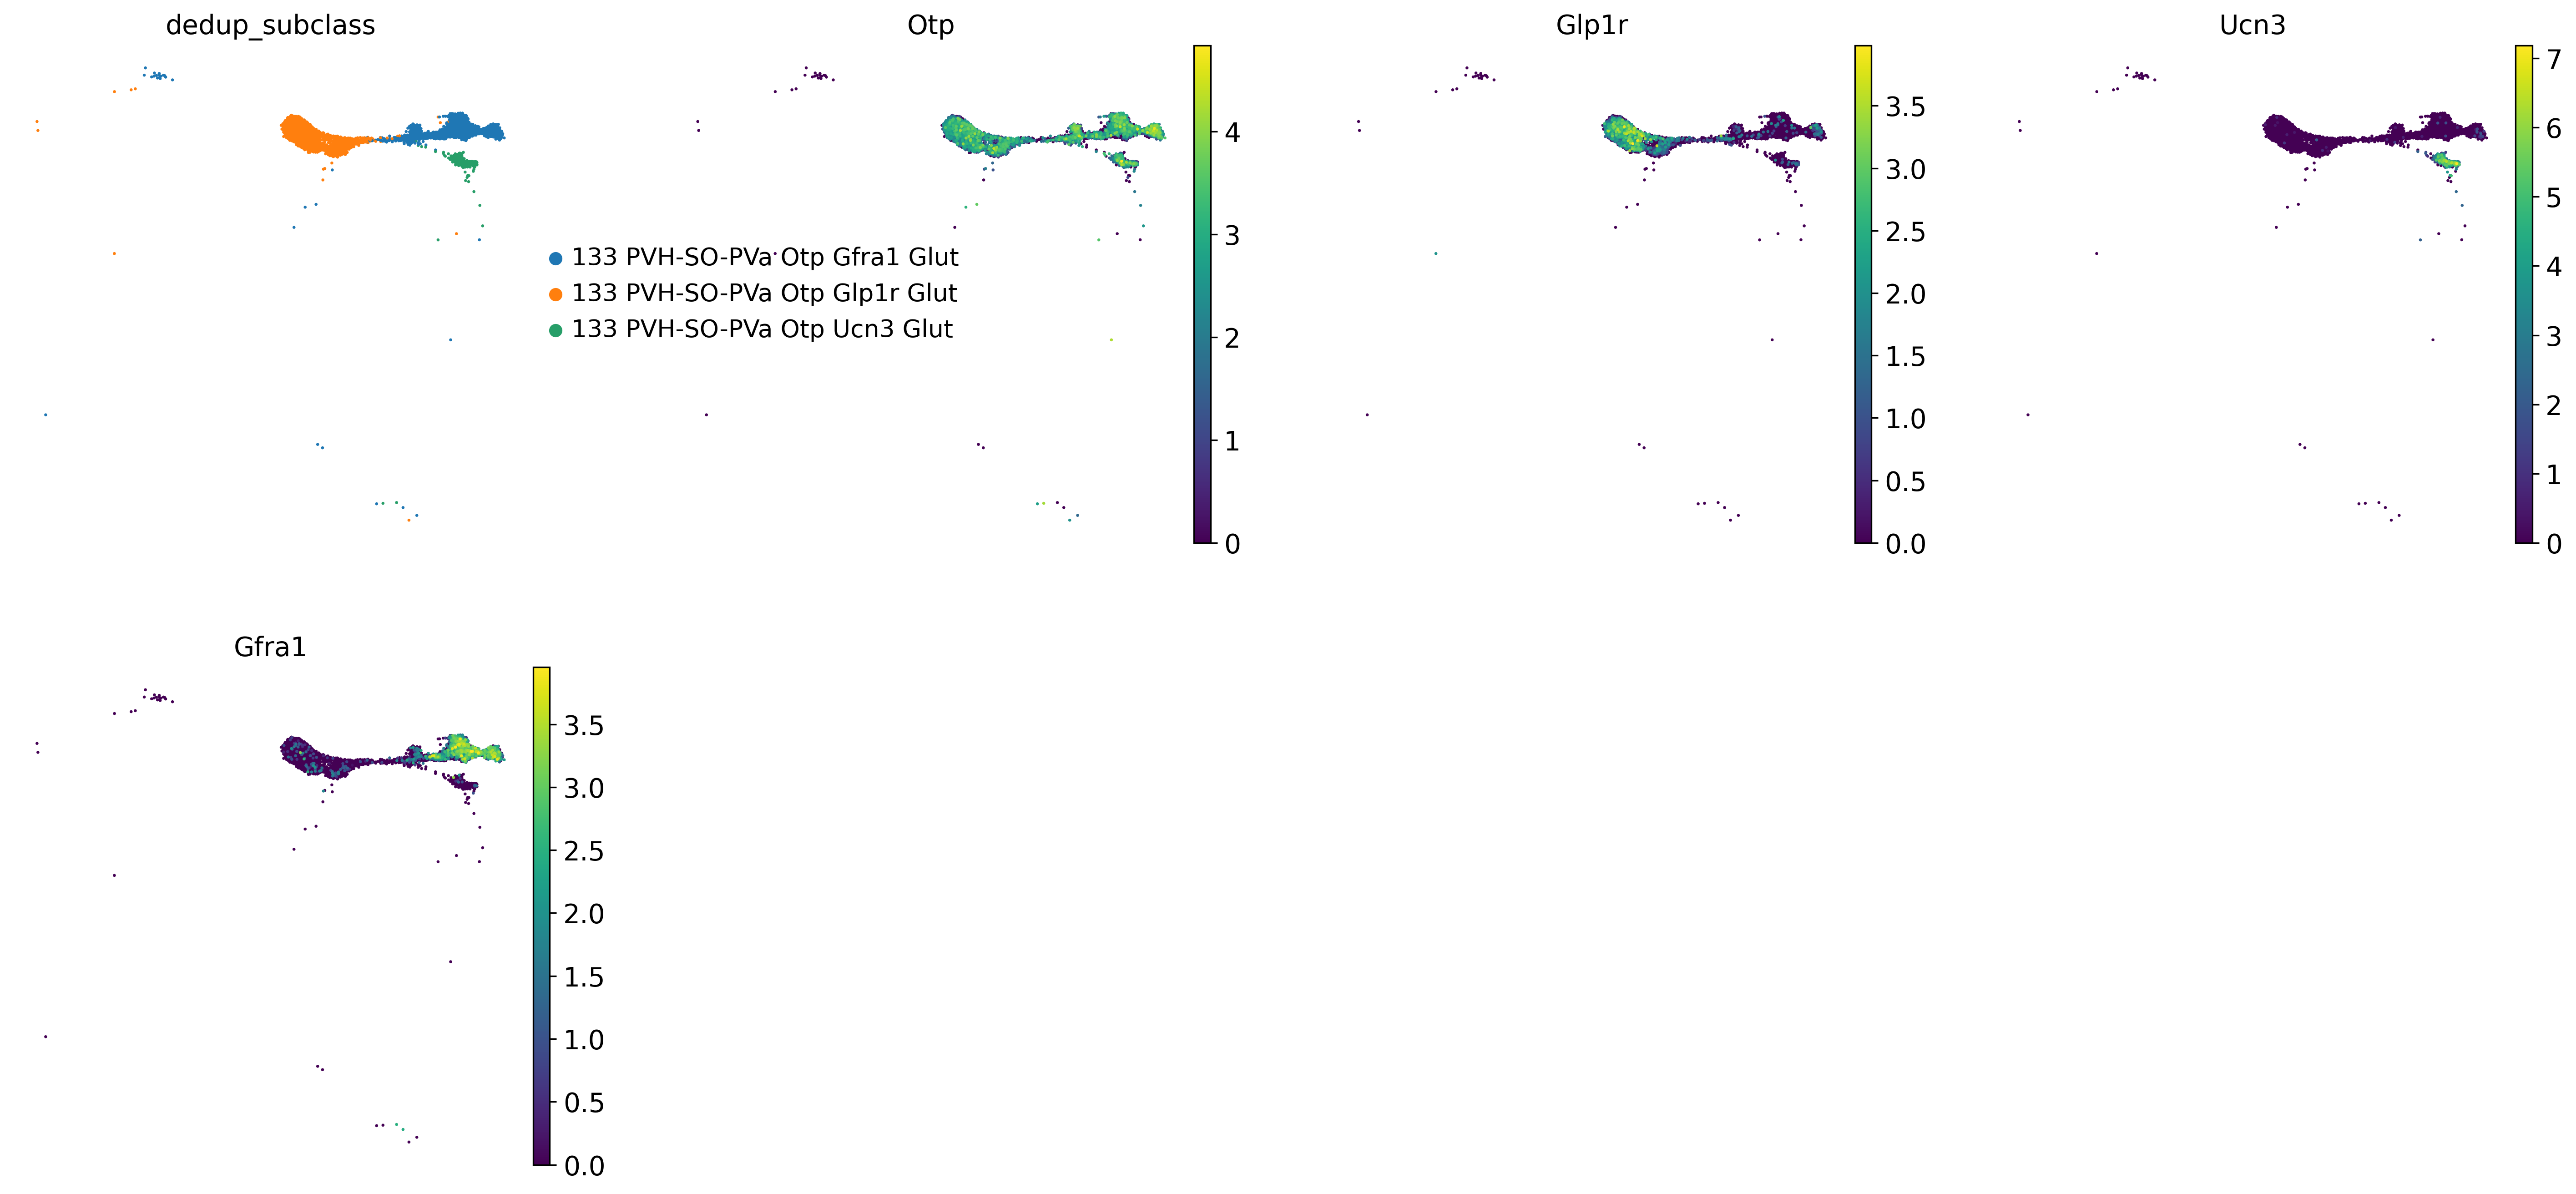

In [22]:

with_all_sisters = False

# Count occurrences
ids = [s.split(" ")[0] for s in list(adata.uns["abc_mapping"]["subclass"].values())]
counts = Counter(ids)

duplicates = set([s for s in ids if counts[s] > 1])

for i_str in duplicates:

    dups = [c for c in list(adata.uns["abc_mapping"]["subclass"].values()) if i_str in c]
    genes = [dups[0].split(" ")[-3]]
    genes.extend([s.split(" ")[-2] for s in dups])
    
    if with_all_sisters:
        # with sisters
        one_of_the_duplicates = strip_cluster_prefix(adata[adata.obs.dedup_subclass == dups[0]].obs.L2.unique()[0])
        sisters = [s.name for s in all_clusters1[one_of_the_duplicates].get_sisters()]
        sisters.append(one_of_the_duplicates)
        sisters = [f"L2: {s}" for s in sisters]
        subset = adata[adata.obs.L2.isin(sisters)]

    else:
        subset = adata[adata.obs.dedup_subclass.isin(dups)]

    sc.pl.umap(subset, color = ["dedup_subclass"] + genes, na_color ="black", layer="log1p")

## Moving on to L3

Here, matches are searched under the constraint that matches can only be ABC supertypes that are children of the subclass match on L2. 

If there are many:1 mappings, they are deduplicated by appending lower case letters.

In [23]:
def extract_inserted_suffix(original: str, deduped: str) -> List[str]:
    """
    Extract the inserted suffix (typically gene names) from the deduplicated label
    by comparing it with the original label.

    Assumes tokens are separated by spaces.

    Returns:
        List[str]: List of inserted tokens (e.g., genes) not present in the original.
    """
    orig_parts = original.split(" ")
    dedup_parts = deduped.split(" ")
    return [token for token in dedup_parts if token not in orig_parts]

In [24]:
def deduplicate_cluster_names_lvl3(cluster_to_label: Dict[str, str]) -> Dict[str, str]:
    """
    Ensures all values (labels) in a cluster-to-label mapping are unique by appending
    alphabetical suffixes ('a', 'b', 'c', ...) to duplicates.

    Parameters:
        cluster_to_label (dict): Mapping from cluster names to ABC labels (e.g., L3 clusters to supertype labels).

    Returns:
        dict: Mapping with deduplicated labels (values).
    """
    from collections import defaultdict

    # Track how many times each label appears
    label_counts = defaultdict(int)
    label_suffix_map = defaultdict(int)
    deduplicated_map = {}

    for cluster, label in cluster_to_label.items():
        label_counts[label] += 1

    # Track usage and assign suffixes to duplicates
    label_usage = defaultdict(int)

    for cluster, label in cluster_to_label.items():
        if label_counts[label] == 1:
            # Unique already, no suffix needed
            deduplicated_map[cluster] = label
        else:
            # Needs suffix
            index = label_usage[label]
            suffix = chr(ord('a') + index)
            new_label = f"{label}{suffix}"
            deduplicated_map[cluster] = new_label
            label_usage[label] += 1

    return deduplicated_map

In [25]:
def get_hierarchy_constrained_mapping_lvl3(
    adata: ad.AnnData,
    hierarchy_df: pd.DataFrame,
    your_level_col: str,
    allen_level_col: str,
    parent_level_col: str,
    parent_allen_col: str,
    allen_parent_id_col: str,
    allen_child_id_col: str,
    overlap_threshold: float = 0.66,
    deduplicate: bool = True,
    verbose: bool = False,
) -> Dict[str, str]:
    """
    Maps your L3 clusters to Allen Brain labels at supertype level, constrained by hierarchy.
    Inherits deduplicated suffixes from parent labels if present.
    """
    data = adata.obs.copy()

    if verbose:
        print(f"\n[INFO] Starting hierarchy-constrained mapping for {your_level_col} → {allen_level_col}")

    overlap_table = pd.crosstab(
        data[your_level_col],
        data[allen_level_col],
        normalize='index'
    )
    

    final_map = {}

    for your_cluster in overlap_table.index:
        if verbose:
            print(f"\n[CLUSTER] Mapping {your_cluster}")

        parent_cluster_mode = data.loc[
            data[your_level_col] == your_cluster, parent_level_col
        ].mode()
        if parent_cluster_mode.empty:
            if verbose: print("  [SKIP] No parent cluster found.")
            continue
        parent_cluster = parent_cluster_mode.iloc[0]
        if verbose: print(f"  [INFO] Parent cluster: {parent_cluster}")

        parent_allen_label_mode = data.loc[
            data[parent_level_col] == parent_cluster, parent_allen_col
        ].mode()
        if parent_allen_label_mode.empty:
            if verbose: print("  [SKIP] No parent Allen label found.")
            continue
        parent_allen_label = parent_allen_label_mode.iloc[0]
        if verbose: print(f"  [INFO] Parent Allen label: {parent_allen_label}")

        parent_id = extract_numeric_id(parent_allen_label)
        if parent_id == -1:
            if verbose: print("  [SKIP] Could not extract numeric ID from parent label.")
            continue

        allowed_child_ids = hierarchy_df.loc[
            hierarchy_df[allen_parent_id_col] == parent_id,
            allen_child_id_col
        ].dropna().astype(int).unique()
        if verbose: print(f"  [INFO] Allowed child IDs under parent {parent_id}: {allowed_child_ids.tolist()}")

        row = overlap_table.loc[your_cluster]
        filtered_row = row[
            [extract_numeric_id(label) in allowed_child_ids for label in row.index]
        ]

        if filtered_row.empty:
            if verbose: print("  [SKIP] No valid child matches after filtering.")
            continue

        best_match = filtered_row.idxmax()
        confidence = filtered_row[best_match]
        if verbose: print(f"  [MATCH] Best match: {best_match} (overlap={confidence:.2f})")

        if confidence >= overlap_threshold:
            original_parent_label_arr = hierarchy_df.loc[
                hierarchy_df[allen_parent_id_col] == parent_id,
                f"{allen_parent_id_col}_label"
            ].unique()

            if len(original_parent_label_arr) == 1:
                original_label = original_parent_label_arr[0]
                if original_label != parent_allen_label:
                    if verbose:
                        print(f"  [DEDUP INHERIT] Parent label was deduplicated:")
                        print(f"    - Original: {original_label}")
                        print(f"    - Deduped:  {parent_allen_label}")
                    
                    inserted = extract_inserted_suffix(original_label, parent_allen_label)
                    if verbose: print(f"    - Inserted suffix: {inserted}")

                    parts = best_match.split(" ")
                    best_match = " ".join(parts[:-1] + inserted + [parts[-1]])
                    if verbose: print(f"  [UPDATED] Inherited child label: {best_match}")
            else:
                if verbose: print("  [WARN] Could not uniquely determine original parent label. Skipping inheritance.")

            final_map[your_cluster] = best_match
        else:
            if verbose: print("  [SKIP] Best match did not exceed overlap threshold.")

    if deduplicate:
        if verbose: print("\n[INFO] Deduplicating final labels...")
        final_map = deduplicate_cluster_names_lvl3(final_map)

    if verbose: print("\n[DONE] Final L3 mapping complete.")
    return final_map



In [26]:
supertype_mapper = get_hierarchy_constrained_mapping_lvl3(
    adata=adata,
    hierarchy_df=allen_table,
    your_level_col="L3",
    allen_level_col="supertype_id_label_propagated",
    parent_level_col="L2",
    parent_allen_col="dedup_subclass",
    allen_parent_id_col="subclass_id",
    allen_child_id_col="supertype_id",
    overlap_threshold=0.66,
    deduplicate = True,
    verbose = True
)



[INFO] Starting hierarchy-constrained mapping for L3 → supertype_id_label_propagated

[CLUSTER] Mapping Gb3-124
  [INFO] Parent cluster: Gb2-39
  [INFO] Parent Allen label: 085 SI-MPO-LPO Lhx8 Gaba
  [INFO] Allowed child IDs under parent 85: [396, 397, 398, 399, 400, 401]
  [MATCH] Best match: 0397 SI-MPO-LPO Lhx8 Gaba_2 (overlap=0.94)

[CLUSTER] Mapping Gb3-125


  [INFO] Parent cluster: Gb2-39
  [INFO] Parent Allen label: 085 SI-MPO-LPO Lhx8 Gaba
  [INFO] Allowed child IDs under parent 85: [396, 397, 398, 399, 400, 401]
  [MATCH] Best match: 0396 SI-MPO-LPO Lhx8 Gaba_1 (overlap=0.28)
  [SKIP] Best match did not exceed overlap threshold.

[CLUSTER] Mapping Gb3-126
  [INFO] Parent cluster: Gb2-39
  [INFO] Parent Allen label: 085 SI-MPO-LPO Lhx8 Gaba
  [INFO] Allowed child IDs under parent 85: [396, 397, 398, 399, 400, 401]
  [MATCH] Best match: 0399 SI-MPO-LPO Lhx8 Gaba_4 (overlap=0.67)

[CLUSTER] Mapping Gb3-127
  [INFO] Parent cluster: Gb2-39
  [INFO] Parent Allen label: 085 SI-MPO-LPO Lhx8 Gaba
  [INFO] Allowed child IDs under parent 85: [396, 397, 398, 399, 400, 401]
  [MATCH] Best match: 0398 SI-MPO-LPO Lhx8 Gaba_3 (overlap=0.86)

[CLUSTER] Mapping Gb3-128
  [INFO] Parent cluster: Gb2-39
  [INFO] Parent Allen label: 085 SI-MPO-LPO Lhx8 Gaba
  [INFO] Allowed child IDs under parent 85: [396, 397, 398, 399, 400, 401]
  [MATCH] Best match: 0400

In [27]:
adata.obs["dedup_supertype"] = adata.obs["L3"].map(supertype_mapper)
adata.uns["abc_mapping"]["supertype"] = supertype_mapper

## Let's sanity check the results

### Preparing some data

In [28]:

mapped_df = adata.obs.loc[:, ["subclass_id_label_propagated", "L2", "dedup_subclass", 
                            "supertype_id_label_propagated", "L3", "dedup_supertype"]]
                            
mapped_df["subclass_id"] = mapped_df["dedup_subclass"].str.extract(r"^(\d+)")
mapped_df["supertype_id"] = mapped_df["dedup_supertype"].str.extract(r"^(\d+)")
mapped_df.head()

,subclass_id_label_propagated,L2,dedup_subclass,supertype_id_label_propagated,L3,dedup_supertype,subclass_id,supertype_id
SC1-01_SAMN18754353_AAACCCACAACCAGAG,129 VMH Nr5a1 Glut,Gl2-35,129 VMH Nr5a1 Acvr1c Glut,0568 VMH Nr5a1 Glut_3,Gl3-113,0568 VMH Nr5a1 Acvr1c Glut_3c,129,0568
SC1-01_SAMN18754353_AAACCCAGTCATCTAG,128 VMH Fezf1 Glut,Gl2-33,128 VMH Fezf1 Glut,0564 VMH Fezf1 Glut_2,Gl3-107,0564 VMH Fezf1 Glut_2,128,0564
SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,129 VMH Nr5a1 Glut,Gl2-35,129 VMH Nr5a1 Acvr1c Glut,0569 VMH Nr5a1 Glut_4,Gl3-111,0568 VMH Nr5a1 Acvr1c Glut_3a,129,0568
SC1-01_SAMN18754353_AAACGAAGTGCGGCTT,129 VMH Nr5a1 Glut,Gl2-35,129 VMH Nr5a1 Acvr1c Glut,0568 VMH Nr5a1 Glut_3,Gl3-113,0568 VMH Nr5a1 Acvr1c Glut_3c,129,0568
SC1-01_SAMN18754353_AAACGAATCGCATAGT,129 VMH Nr5a1 Glut,Gl2-35,129 VMH Nr5a1 Acvr1c Glut,0568 VMH Nr5a1 Glut_3,Gl3-114,0568 VMH Nr5a1 Acvr1c Glut_3d,129,0568


### check that lower level mapping can only exist if upper level one exists

In [29]:

# supertype_id must not exist without subclass_id
invalid_supertype_rows = mapped_df[
    mapped_df["supertype_id"].notna() & mapped_df["subclass_id"].isna()
]

# Display results
print(f"Rows with supertype_id but no subclass_id: {len(invalid_supertype_rows)}")
#print(invalid_supertype_rows)

Rows with supertype_id but no subclass_id: 0


### check that abc hierarchy has been preserved

In [30]:
# Filter only rows where supertype_id is defined (these are the ones to validate)
mapped_with_supertype = mapped_df[mapped_df["supertype_id"].notna()].copy()

# Ensure numeric types for merging
mapped_with_supertype["subclass_id"] = pd.to_numeric(mapped_with_supertype["subclass_id"], errors="coerce")
mapped_with_supertype["supertype_id"] = pd.to_numeric(mapped_with_supertype["supertype_id"], errors="coerce")

# Get valid subclass-supertype pairs from Allen hierarchy
valid_subclass_supertype = allen_table[["subclass_id", "supertype_id"]].drop_duplicates()

# Merge and check which mappings are invalid
merged_supertype_check = mapped_with_supertype.merge(
    valid_subclass_supertype,
    on=["subclass_id", "supertype_id"],
    how="left",
    indicator=True
)

# Report invalid mappings
invalid_supertype_mappings = merged_supertype_check[merged_supertype_check["_merge"] == "left_only"]

print("Invalid supertype ↔ subclass mappings:")
if len(invalid_supertype_mappings) == 0:
    print("None")
else:
    print(invalid_supertype_mappings)

Invalid supertype ↔ subclass mappings:
None


### check if deduplicated hierarchy has been preserved

In [31]:

# Check if each dedup_supertype has only one unique dedup_subclass
supertype_to_subclass = mapped_df.groupby('dedup_supertype')['dedup_subclass'].nunique()
valid_supertype_to_subclass = (supertype_to_subclass <= 1).all()

# Output results
print("Each dedup_supertype maps to one unique dedup_subclass:", valid_supertype_to_subclass)

# Find violations in supertype -> subclass
violating_supertype_to_subclass = supertype_to_subclass[supertype_to_subclass > 1]
print("Violations in supertype to subclass mapping:")
if len(violating_supertype_to_subclass) == 0:
    print("None")
else:
    rint(violating_supertype_to_subclass)


Each dedup_supertype maps to one unique dedup_subclass: True
Violations in supertype to subclass mapping:
None


### check that the dedup supertype associated L3 values map to one L2 parent

In [32]:
# Step 1: Create a mapping from dedup_supertype to its unique L3 values
supertype_to_L3 = mapped_df.groupby('dedup_supertype')['L3'].unique()

# Step 2: For each dedup_supertype, get all associated L2 values via its L3s
violations = {}

for supertype, l3_values in supertype_to_L3.items():
    # Filter rows with any of the L3 values
    l2_values = mapped_df[mapped_df['L3'].isin(l3_values)]['L2'].unique()
    
    if len(l2_values) > 1:
        # Store violations with the actual L2 values
        violations[supertype] = l2_values

# Output the results
if violations:
    print("Violations found: Some dedup_supertypes map to multiple L2 values through their L3s:")
    for supertype, l2_vals in violations.items():
        print(f"- {supertype} → L2 values: {list(l2_vals)}")
else:
    print("All dedup_supertypes map to a single unique L2 through their L3 values.")

All dedup_supertypes map to a single unique L2 through their L3 values.


### check the above for the dedups as parent

In [33]:

# Check dedup_supertype → L3 → dedup_subclass consistency
violations_supertype_to_subclass = {}

# Step 1: Get unique L3s per dedup_supertype
supertype_to_L3 = mapped_df.groupby('dedup_supertype')['L3'].unique()

for supertype, l3_values in supertype_to_L3.items():
    # Step 2: Get dedup_subclass values associated with those L3s
    subclasses = mapped_df[mapped_df['L3'].isin(l3_values)]['dedup_subclass'].unique()
    
    if len(subclasses) > 1:
        violations_supertype_to_subclass[supertype] = subclasses

if violations_supertype_to_subclass:
    print("Violations in dedup_supertype → L3 → dedup_subclass:")
    for supertype, subclasses in violations_supertype_to_subclass.items():
        print(f"- {supertype} → dedup_subclasses: {list(subclasses)}")
else:
    print("All dedup_supertypes map to a single unique dedup_subclass via their L3s.")

All dedup_supertypes map to a single unique dedup_subclass via their L3s.


### check that there are no non-duplicated version mapped somewhere else

In [34]:

# Check that all dedup_supertype strings under a supertype_id have consistent structure (same number of tokens)
violations_structure = {}

# Group by supertype_id and get unique dedup_supertype values
grouped = mapped_df.groupby('supertype_id')['dedup_supertype'].unique()

for supertype_id, dedup_supertypes in grouped.items():
    # Count number of tokens in each unique dedup_supertype string
    token_lengths = [len(s.split()) for s in dedup_supertypes]
    
    if len(set(token_lengths)) > 1:
        violations_structure[supertype_id] = {
            'lengths': token_lengths,
            'dedup_supertypes': list(dedup_supertypes)
        }

# Print results
if violations_structure:
    print("Violations: Inconsistent token counts in dedup_supertype strings per supertype_id:")
    for sid, info in violations_structure.items():
        print(f"- supertype_id {sid}: token lengths = {info['lengths']}")
        for ds in info['dedup_supertypes']:
            print(f"    • {ds}")
else:
    print("All dedup_supertype strings have consistent token structure within each supertype_id.")

All dedup_supertype strings have consistent token structure within each supertype_id.


### check all duplications

In [35]:

def print_duplicate_mappings_by_id_prefix(mapping: dict, level_name: str = ""):
    """
    Print all mappings where different input clusters were mapped to ABC clusters with the same ID prefix.

    Parameters:
        mapping (dict): Your-to-ABC mapping, e.g., adata.uns["abc_mapping"]["class"]
        level_name (str): Optional name of the level, for clearer output.
    """
    id_to_clusters = defaultdict(list)

    for cluster, abc_label in mapping.items():
        # Extract ID prefix (assumes it starts the string)
        match = re.match(r"^(\d+)", abc_label)
        if match:
            abc_id = match.group(1)
            id_to_clusters[abc_id].append((cluster, abc_label))

    print(f"\nDuplicate ABC IDs in mapping [{level_name}]:\n")
    has_duplicates = False
    for abc_id, entries in id_to_clusters.items():
        if len(entries) > 1:
            has_duplicates = True
            print(f"ABC ID {abc_id} is used in:")
            for cluster, label in entries:
                print(f"  - Cluster '{cluster}' → '{label}'")
            print()

    if not has_duplicates:
        print("No duplicate ABC ID prefixes found.\n")

print_duplicate_mappings_by_id_prefix(adata.uns["abc_mapping"]["subclass"], level_name="subclass")
print_duplicate_mappings_by_id_prefix(adata.uns["abc_mapping"]["supertype"], level_name="supertype")


Duplicate ABC IDs in mapping [subclass]:

ABC ID 101 is used in:
  - Cluster 'Gb2-41' → '101 ZI Pax6 Pou6f2 Gaba'
  - Cluster 'Gb2-50' → '101 ZI Pax6 Nfib Gaba'

ABC ID 106 is used in:
  - Cluster 'Gb2-46' → '106 PVpo-VMPO-MPN Hmx2 Esr1 Gaba'
  - Cluster 'Gb2-53' → '106 PVpo-VMPO-MPN Hmx2 Isl1 Gaba'

ABC ID 107 is used in:
  - Cluster 'Gb2-49' → '107 DMH Hmx2 Lef1 Gaba'
  - Cluster 'Gb2-54' → '107 DMH Hmx2 Zfp536 Gaba'

ABC ID 097 is used in:
  - Cluster 'Gb2-55' → '097 PVHd-SBPV Six3 Prox1 Meis2 Gaba'
  - Cluster 'Gb2-62' → '097 PVHd-SBPV Six3 Prox1 Pitx2 Gaba'

ABC ID 104 is used in:
  - Cluster 'Gb2-56' → '104 TU-ARH Otp Six6 Foxp2 Gaba'
  - Cluster 'Gb2-63' → '104 TU-ARH Otp Six6 Npy2r Gaba'
  - Cluster 'Gb2-68' → '104 TU-ARH Otp Six6 Fgf10 Gaba'

ABC ID 133 is used in:
  - Cluster 'Gl2-2' → '133 PVH-SO-PVa Otp Glp1r Glut'
  - Cluster 'Gl2-8' → '133 PVH-SO-PVa Otp Ucn3 Glut'
  - Cluster 'Gl2-27' → '133 PVH-SO-PVa Otp Gfra1 Glut'

ABC ID 139 is used in:
  - Cluster 'Gl2-3' → '139 P

## Let's get the L2 labels for all clusters not mapping to ABC

### Get most likely regions for the L2 clusters not mapping to ABC

In [36]:

def map_likely_regions(cluster: str, regions_df: pd.DataFrame, mass_threshold: float = 0.33) -> str:
    """
    Given a cluster name and a DataFrame of region data, returns a string 
    combining up to three nuclei names needed to exceed a specified cumulative relative_mass.

    The function:
    - Filters the DataFrame for rows matching the given cluster.
    - Sorts by relative_mass in descending order.
    - Selects up to 3 nuclei, accumulating relative_mass until the specified threshold is exceeded.
    - Joins selected nuclei with hyphens ("-").

    Parameters
    ----------
    cluster : str
        The name of the cluster to filter by.

    regions_df : pd.DataFrame
        A DataFrame containing the following columns:
            - 'cluster': str, the cluster identifier.
            - 'acronym': str, the name of the nucleus.
            - 'relative_mass': float, the mass contribution (can be NaN).

    mass_threshold : float, optional (default=0.33)
        The cumulative relative_mass threshold to reach or exceed.

    Returns
    -------
    str
        A hyphen-separated string of up to 3 nucleus names contributing to > threshold 
        cumulative relative_mass, ordered by descending mass.
        Returns an empty string if no valid nuclei are found.
    """
    # Filter rows matching the cluster
    cluster_df = regions_df[regions_df['cluster'] == cluster].copy()

    # Drop rows where 'relative_mass' is NaN
    cluster_df = cluster_df.dropna(subset=['relative_mass'])

    # Remove fiber tracts (all lowercase nuclei names)
    cluster_df = cluster_df[~cluster_df['acronym'].str.islower()]

    # Sort by relative_mass descending
    cluster_df = cluster_df.sort_values(by='relative_mass', ascending=False)

    # Accumulate relative_mass until threshold is exceeded, capped at 3 nuclei
    cumulative_mass = 0.0
    selected_nuclei = []

    for _, row in cluster_df.iterrows():
        cumulative_mass += row['relative_mass']
        selected_nuclei.append(row['acronym'])
        if cumulative_mass > mass_threshold or len(selected_nuclei) == 3:
            break

    return "-".join(selected_nuclei)


In [37]:

#regions = regions.loc[~regions.cluster.apply(lambda x: "Vicinity" in x or "NN" in x),:]
regions["subclass"]= regions.cluster.map(adata.uns["abc_mapping"]["subclass"])
regions["allen_nuclei"] = regions.subclass.apply(
    lambda x: x.split(" ")[1].split("-") if isinstance(x, str) and pd.notna(x) else None
)

regions["region_string"] = regions.cluster.apply(lambda x: map_likely_regions(x, regions_df = regions, mass_threshold=0.33))
region_mapper = regions[["cluster", "region_string"]].drop_duplicates().set_index("cluster").to_dict()["region_string"]

In [38]:
regions.head()

,cluster,acronym,relative_mass,subclass,allen_nuclei,region_string
1971,Gl2-9,LHA,0.227223,130 LHA Pmch Glut,[LHA],LHA-DMH-ZI
7819,Gl2-9,DMH,0.073761,130 LHA Pmch Glut,[LHA],LHA-DMH-ZI
7615,Gl2-9,ZI,0.067902,130 LHA Pmch Glut,[LHA],LHA-DMH-ZI
3331,Gl2-9,MB,0.058605,130 LHA Pmch Glut,[LHA],LHA-DMH-ZI
1427,Gl2-9,MRN,0.039889,130 LHA Pmch Glut,[LHA],LHA-DMH-ZI


### Let's assign new L2 for clusters not mapping to ABC

In [39]:
def assign_l2_new_labels(
    adata: ad.AnnData,
    gene_df: pd.DataFrame,
    brain_region_mapper: Dict[str, str],
    use_NN_propagated: bool = True
) -> None:
    """
    Create new subclass labels in `adata.obs['L2_new']` for L2 clusters without existing mappings.

    For each unmapped L2 cluster, assign a label:
        <brain_region> <gene> <neurotransmitter>

    If two clusters share the same brain region and neurotransmitter, ensure unique gene usage.
    """
    obs = adata.obs.copy()

    # Step 1: Initialize with existing deduplicated labels
    if 'dedup_subclass' in obs.columns:
        obs['L2_new'] = obs['dedup_subclass'].where(obs['dedup_subclass'].notna(), np.nan).astype(object)
    else:
        obs['L2_new'] = pd.Series(index=obs.index, dtype='object')

    # Step 2: Optionally propagate NN labels
    if use_NN_propagated and 'subclass_id_label_propagated' in obs.columns:
        obs['subclass_id_label_propagated'] = obs['subclass_id_label_propagated'].astype(str)
        nn_mask = obs['subclass_id_label_propagated'].str.contains("NN", na=False)
        obs.loc[nn_mask, 'L2_new'] = obs.loc[nn_mask, 'subclass_id_label_propagated']

    # Step 3: Assign new labels to unmapped clusters
    unmapped_clusters = obs.loc[obs['L2_new'].isna(), 'L2'].unique()
    used_gene_combinations = set()

    for cluster in unmapped_clusters:
        #print(cluster)
        cluster_mask = obs['L2'] == cluster

        # Get region and neurotransmitter
        brain_region = brain_region_mapper.get(cluster, "UnknownRegion")

        # Neurotransmitter
        neurotransmitter = "Glut" if cluster[:2] == "Gl" else 'GABA'

        # Try genes in descending order of specificity until a unique label is found
        gene_list = gene_df[(gene_df['cluster'] == cluster) & (gene_df["direction"] == "A")] \
            .sort_values("specificity", ascending=False)["gene_name"].tolist()

        for gene in gene_list:
            label_candidate = (brain_region, gene, neurotransmitter)
            if label_candidate not in used_gene_combinations:
                used_gene_combinations.add(label_candidate)
                label_str = f"{brain_region} {gene} {neurotransmitter}"
                obs.loc[cluster_mask, 'L2_new'] = label_str
                break
        else:
            # Fallback: use unknown gene with a unique numeric suffix
            fallback_gene = f"UnknownGene_{cluster}"
            label_str = f"{brain_region} {fallback_gene} {neurotransmitter}"
            obs.loc[cluster_mask, 'L2_new'] = label_str
            used_gene_combinations.add((brain_region, fallback_gene, neurotransmitter))

    # Write back
    adata.obs['L2_new'] = obs['L2_new']

    if adata.obs['L2_new'].isna().any():
        print("[WARNING] Some cells in 'L2_new' are still NaN")


In [40]:
assign_l2_new_labels(
    adata = adata,
    gene_df = markers,
    brain_region_mapper = region_mapper,
    use_NN_propagated = False)

In [41]:
#sorted(adata.obs.L2_new.unique())

## Let's move on to L3

Critically, if there is a match for L2 and subclass but no match for a L3, then the suffix for L3 must start at the maximum idx that was available from ABC supertypes that are children of the subclass match of L2

In [42]:
def assign_l3_new_labels(
    adata: ad.AnnData,
    hierarchy_df: pd.DataFrame,
    use_NN_propagated: bool = True,
    verbose: bool = False
) -> None:
    """
    Assign new labels to L3 clusters that do not have a mapped supertype.

    Parameters:
        adata (AnnData): AnnData object with obs containing L2, L2_new, L3, dedup_supertype.
        hierarchy_df (pd.DataFrame): DataFrame with Allen hierarchy (must contain 'subclass_id' and 'supertype_id_label').
        use_NN_propagated (bool): If True, propagate 'NN' labels from ABC_supertype_propagated.
        verbose (bool): If True, print detailed output.
    """

    obs = adata.obs.copy()

    if verbose:
        print("\n[INFO] Assigning new L3 labels...")

    # Step 1: Start from deduplicated supertype
    if 'dedup_supertype' in obs.columns:
        obs['L3_new'] = obs['dedup_supertype'].where(obs['dedup_supertype'].notna(), np.nan).astype(object)
    else:
        obs['L3_new'] = pd.Series(index=obs.index, dtype='object')

    # Step 2: Optionally propagate NN labels
    if use_NN_propagated and 'supertype_id_label_propagated' in obs.columns:
        obs['supertype_id_label_propagated'] = obs['supertype_id_label_propagated'].astype(str)
        nn_mask = obs['supertype_id_label_propagated'].str.contains("NN", na=False)
        obs.loc[nn_mask, 'L3_new'] = obs.loc[nn_mask, 'supertype_id_label_propagated']
        if verbose:
            print(f"[INFO] Propagated {nn_mask.sum()} NN labels from supertype_id_label_propagated")

    # Step 3: Identify unmapped clusters
    unmapped_clusters = obs.loc[obs['L3_new'].isna(), 'L3'].unique()
    if verbose:
        print(f"[INFO] Found {len(unmapped_clusters)} L3 clusters without mappings")

    # Step 4: Map each L3 cluster to its L2_new label
    cluster_to_l2_new = {}
    for cluster in unmapped_clusters:
        cluster_mask = obs['L3'] == cluster
        l2_values = obs.loc[cluster_mask, 'L2_new'].dropna().astype(str).unique()

        if len(l2_values) == 1:
            cluster_to_l2_new[cluster] = l2_values[0]
        else:
            cluster_to_l2_new[cluster] = "UnknownParent"
            if verbose:
                print(f"[WARN] Cluster {cluster} has ambiguous or missing L2_new label")

    # Step 5: Group L3 clusters by L2_new label
    l2_to_l3_clusters = defaultdict(list)
    for l3_cluster, l2_label in cluster_to_l2_new.items():
        l2_to_l3_clusters[l2_label].append(l3_cluster)

    # Step 6: Assign unique labels starting from max + 1 of supertype suffix
    for l2_label, l3_clusters in l2_to_l3_clusters.items():
        start_index = 1  # Default start

        # If label starts with subclass ID and is not NN, try parsing
        if isinstance(l2_label, str) and not "NN" in l2_label and re.match(r"^\d+", l2_label):
            subclass_id_str = re.match(r"^\d+", l2_label).group()
            subclass_id = int(subclass_id_str.lstrip("0") or "0")

            # Pull relevant supertype label strings for this subclass
            supertype_labels = hierarchy_df.loc[
                hierarchy_df["subclass_id"] == subclass_id,
                "supertype_id_label"
            ].dropna().unique()

            suffix_numbers = []
            for label in supertype_labels:
                if isinstance(label, str) and "_" in label:
                    try:
                        suffix = int(label.strip().split("_")[-1])
                        suffix_numbers.append(suffix)
                    except ValueError:
                        continue

            if suffix_numbers:
                start_index = max(suffix_numbers) + 1
                if verbose:
                    print(f"[INFO] L2 '{l2_label}' → Starting suffix: {start_index} (from hierarchy)")

        # Assign deduplicated names
        for i, l3_cluster in enumerate(sorted(l3_clusters), start=start_index):
            new_label = f"{l2_label}_{i}"
            obs.loc[obs['L3'] == l3_cluster, 'L3_new'] = new_label
            if verbose:
                print(f"[ASSIGN] Cluster {l3_cluster} → {new_label}")

    # Step 7: Commit updates to adata
    adata.obs['L3_new'] = obs['L3_new']

    if verbose:
        print("\n[DONE] Finished assigning L3_new labels.\n")


In [43]:
assign_l3_new_labels(
    adata = adata,    
    hierarchy_df = allen_table,
    use_NN_propagated = False,
    verbose = True) 


[INFO] Assigning new L3 labels...
[INFO] Found 102 L3 clusters without mappings
[INFO] L2 '128 VMH Fezf1 Glut' → Starting suffix: 4 (from hierarchy)
[ASSIGN] Cluster Gl3-106 → 128 VMH Fezf1 Glut_4
[INFO] L2 '129 VMH Nr5a1 Nfix Glut' → Starting suffix: 7 (from hierarchy)
[ASSIGN] Cluster Gl3-110 → 129 VMH Nr5a1 Nfix Glut_7
[ASSIGN] Cluster Gl3-69 → VPM-PO-MD Pax6 Glut_1
[ASSIGN] Cluster Gl3-70 → VPM-PO-MD Pax6 Glut_2
[INFO] L2 '100 AHN Onecut3 Gaba' → Starting suffix: 4 (from hierarchy)
[ASSIGN] Cluster Gb3-223 → 100 AHN Onecut3 Gaba_4
[ASSIGN] Cluster Gb3-224 → 100 AHN Onecut3 Gaba_5
[ASSIGN] Cluster Gb3-226 → 100 AHN Onecut3 Gaba_6
[INFO] L2 '104 TU-ARH Otp Six6 Foxp2 Gaba' → Starting suffix: 4 (from hierarchy)
[ASSIGN] Cluster Gb3-204 → 104 TU-ARH Otp Six6 Foxp2 Gaba_4
[ASSIGN] Cluster Gl3-13 → LHA-PH-MB Rreb1 Glut_1
[INFO] L2 '099 SBPV-PVa Six6 Satb2 Gaba' → Starting suffix: 4 (from hierarchy)
[ASSIGN] Cluster Gb3-243 → 099 SBPV-PVa Six6 Satb2 Gaba_4
[INFO] L2 '089 PVR Six3 Sox3 Ga

## Moving on to L4

Here, we just start with our own enumeration

In [44]:
def assign_l4_new_labels(adata: ad.AnnData) -> None:
    """
    Assigns new unique labels at L4 level based on L3_new labels.
    Always appends dash-number suffixes, e.g. '-1', '-2', even if only one cluster maps to a given L3_new.
    Adds: adata.obs['L4_new']
    """
    l4_clusters = sorted(
        adata.obs["L4"].unique(),
        key=lambda x: tuple(map(int, re.findall(r"\d+", str(x))))
    )
    mapping = {}

    for cluster in l4_clusters:
        l3_vals = adata.obs.loc[adata.obs["L4"] == cluster, "L3_new"].dropna().unique()

        if len(l3_vals) == 1:
            mapping[cluster] = l3_vals[0]
        elif len(l3_vals) > 1:
            if any("NN" in val for val in l3_vals):
                mapping[cluster] = "Unknown_NN_L3"
            else:
                mapping[cluster] = "UnknownL3"
        else:
            mapping[cluster] = "UnknownL3"

    adata.obs["L4_new"] = adata.obs["L4"].map(mapping)

    # Always append "-<number>"
    from collections import defaultdict

    label_counts = defaultdict(int)
    new_labels = {}

    for cluster in l4_clusters:
        base = mapping[cluster]
        label_counts[base] += 1
        new_labels[cluster] = f"{base}-{label_counts[base]}"

    adata.obs["L4_new"] = adata.obs["L4"].map(new_labels)

In [45]:
assign_l4_new_labels(adata)

## Moving on to L5

same as above

In [46]:
def assign_l5_new_labels(adata: ad.AnnData) -> None:
    """
    Assigns new unique labels at L5 level based on L4_new labels.
    Always appends dash-number suffixes, e.g. '-1', '-2', even if only one cluster maps to a given L4_new.
    Adds: adata.obs['L5_new']
    """
    l5_clusters = sorted(
        adata.obs["L5"].unique(),
        key=lambda x: tuple(map(int, re.findall(r"\d+", str(x))))
    )
    mapping = {}

    for cluster in l5_clusters:
        l4_vals = adata.obs.loc[adata.obs["L5"] == cluster, "L4_new"].dropna().unique()

        if len(l4_vals) == 1:
            mapping[cluster] = l4_vals[0]
        elif len(l4_vals) > 1:
            if any("NN" in val for val in l4_vals):
                mapping[cluster] = "Unknown_NN_L4"
            else:
                mapping[cluster] = "UnknownL4"
        else:
            mapping[cluster] = "UnknownL4"

    adata.obs["L5_new"] = adata.obs["L5"].map(mapping)

    # Always append ".<number>"
    from collections import defaultdict

    label_counts = defaultdict(int)
    new_labels = {}

    for cluster in l5_clusters:
        base = mapping[cluster]
        label_counts[base] += 1
        new_labels[cluster] = f"{base}-{label_counts[base]}"

    adata.obs["L5_new"] = adata.obs["L5"].map(new_labels)


In [47]:
assign_l5_new_labels(adata)

In [48]:
#sorted(adata.obs.L5_new.unique())

## Let's add the IDs

In [49]:


def finalize_label_strings(
    adata: ad.AnnData,
    verbose: bool = False
) -> None:
    """
    Finalize labels in L1_new to L5_new columns by:
    - Stripping any leading numeric ID tokens
    - Replacing 'Gaba' with 'GABA'
    - Adding the original IDs as prefix
    """

    for level in range(2,6): 
        if verbose:
            print(f"\n[PROCESSING] Finalizing labels for L{level}...")

        # Convert to string and fix 'Gaba' → 'GABA'
        adata.obs[f"L{level}_new"] = adata.obs[f"L{level}_new"].astype(str).str.replace("Gaba", "GABA")

        # Strip leading numbers (e.g., "104 SOM GABA" → "SOM GABA")
        adata.obs[f"L{level}_new"]  = adata.obs[f"L{level}_new"].str.replace(r"^\d+\s*", "", regex=True)

        # Assign new IDs
        adata.obs[f"L{level}_new"] = adata.obs.apply(lambda row: row[f"L{level}"] + " " + row[f"L{level}_new"], axis=1)

        if verbose:
            print(f"[DONE] Finalized L{level} with {adata.obs[f'L{level}_new'].nunique()} unique labels.")



In [50]:
finalize_label_strings(adata= adata, )

In [51]:
labelmat = adata.obs.loc[:, ["L1", "L2_new", "L3_new", "L4_new", "L5_new"]]
labelmat.columns = [f"L{i}_abc_like" for i in range(1,6)]

In [52]:
labelmat

,L1_abc_like,L2_abc_like,L3_abc_like,L4_abc_like,L5_abc_like
SC1-01_SAMN18754353_AAACCCACAACCAGAG,Gl1-1 Glut,Gl2-35 VMH Nr5a1 Acvr1c Glut,Gl3-113 VMH Nr5a1 Acvr1c Glut_3c,Gl4-290 VMH Nr5a1 Acvr1c Glut_3c-1,Gl5-390 VMH Nr5a1 Acvr1c Glut_3c-1-1
SC1-01_SAMN18754353_AAACCCAGTCATCTAG,Gl1-1 Glut,Gl2-33 VMH Fezf1 Glut,Gl3-107 VMH Fezf1 Glut_2,Gl4-274 VMH Fezf1 Glut_2-2,Gl5-371 VMH Fezf1 Glut_2-2-1
SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,Gl1-1 Glut,Gl2-35 VMH Nr5a1 Acvr1c Glut,Gl3-111 VMH Nr5a1 Acvr1c Glut_3a,Gl4-286 VMH Nr5a1 Acvr1c Glut_3a-4,Gl5-386 VMH Nr5a1 Acvr1c Glut_3a-4-1
SC1-01_SAMN18754353_AAACGAAGTGCGGCTT,Gl1-1 Glut,Gl2-35 VMH Nr5a1 Acvr1c Glut,Gl3-113 VMH Nr5a1 Acvr1c Glut_3c,Gl4-291 VMH Nr5a1 Acvr1c Glut_3c-2,Gl5-391 VMH Nr5a1 Acvr1c Glut_3c-2-1
SC1-01_SAMN18754353_AAACGAATCGCATAGT,Gl1-1 Glut,Gl2-35 VMH Nr5a1 Acvr1c Glut,Gl3-114 VMH Nr5a1 Acvr1c Glut_3d,Gl4-297 VMH Nr5a1 Acvr1c Glut_3d-3,Gl5-398 VMH Nr5a1 Acvr1c Glut_3d-3-2
...,...,...,...,...,...
SC2-25_SAMN46505609_TTTGTTGGTCACTCGC,Gb1-2 GABA,Gb2-56 TU-ARH Otp Six6 Foxp2 GABA,Gb3-206 TU-ARH Otp Six6 Foxp2 GABA_2b,Gb4-563 TU-ARH Otp Six6 Foxp2 GABA_2b-1,Gb5-740 TU-ARH Otp Six6 Foxp2 GABA_2b-1-2
SC2-25_SAMN46505609_TTTGTTGGTGCGCGTA,Gl1-1 Glut,Gl2-32 ARH-PVp Tbx3 Isl1 Glut,Gl3-102 ARH-PVp Tbx3 Isl1 Glut_2a,Gl4-255 ARH-PVp Tbx3 Isl1 Glut_2a-1,Gl5-347 ARH-PVp Tbx3 Isl1 Glut_2a-1-2
SC2-25_SAMN46505609_TTTGTTGGTGGGTGAA,Gl1-1 Glut,Gl2-12 PH-SUM Foxa1 Glut,Gl3-29 PH-SUM Foxa1 Glut_6,Gl4-73 PH-SUM Foxa1 Glut_6-2,Gl5-95 PH-SUM Foxa1 Glut_6-2-2
SC2-25_SAMN46505609_TTTGTTGGTGTTTGAG,Gl1-1 Glut,Gl2-33 VMH Fezf1 Glut,Gl3-106 VMH Fezf1 Glut_4,Gl4-268 VMH Fezf1 Glut_4-1,Gl5-365 VMH Fezf1 Glut_4-1-1


In [55]:
labelmat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 607093 entries, SC1-01_SAMN18754353_AAACCCACAACCAGAG to SC2-25_SAMN46505609_TTTGTTGGTGTTTGTC
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype   
---  ------       --------------   -----   
 0   L1_abc_like  607093 non-null  category
 1   L2_abc_like  607093 non-null  object  
 2   L3_abc_like  607093 non-null  object  
 3   L4_abc_like  607093 non-null  object  
 4   L5_abc_like  607093 non-null  object  
dtypes: category(1), object(4)
memory usage: 39.9+ MB


## Saving

In [56]:
labelmat.to_csv(OUTDIR / "abc_like_annotation.csv")